# Transaction Risk Scoring

Fraud detection on **590,540 IEEE-CIS transactions**, comparing XGBoost, LightGBM, and a PyTorch autoencoder with chronological evaluation, SHAP explanations, and local MLflow tracking.

The validation-selected ensemble achieved **0.5517 average precision**, **0.9017 ROC-AUC**, **68.3% precision**, and **46.0% recall** on the chronological test period. Section 7 contains the controlled comparison and complete candidate results. Earlier experiments are retained to document the evaluation history; the test period has been reused across studies.

## Execution

Install `requirements.txt` and place `train_transaction.csv` and `train_identity.csv` under `data/`. Open this notebook from the repository root. All project implementation code is included below.

Embedded results and charts come from completed model runs. The consolidated notebook has passed syntax and structure checks; a full Jupyter kernel run remains unverified.

By default, `RUN_TRAINING = False` displays saved results without retraining. Set it to `True` to reproduce the baseline under `output/notebook_run/`. Section 6 provides `RUN_IMPROVEMENTS` for the first follow-up. Section 7 provides `RUN_CONTROLLED` for the controlled comparison and `RUN_RANDOM_DIAGNOSTIC` for the optional split diagnostic. Training refuses to overwrite frozen evaluations; scoring demonstrations require fresh artifacts.


In [ ]:
from pathlib import Path
from types import SimpleNamespace
from datetime import datetime, timezone
import copy
import importlib.metadata
import json
import platform
import time

import joblib
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, confusion_matrix, precision_score, recall_score, f1_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

# Load tree backends before PyTorch for consistent native CPU runtime initialization.
import xgboost
import lightgbm
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

torch.set_num_threads(1)
SEED = 42
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    raise FileNotFoundError("Run this notebook from the project root with the CSVs in data/.")
# Separate reproduction outputs preserve the original reported experiment.
DEFAULT_OUT = ROOT / "output/notebook_run/supervised"
AE_OUT = ROOT / "output/notebook_run/autoencoder"
NUMERIC_IDENTIFIERS = {"card1", "card2", "card3", "card5", "addr1", "addr2"}
RUN_TRAINING = False

# Embedded reference results remain available even when training is disabled.
import base64
REPORTED = json.loads((ROOT / "transaction-risk-scoring.ipynb").read_text())["metadata"]["reported_results"]


## 1. Data and evaluation design

The transaction and identity tables are joined one-to-one by TransactionID, retaining every transaction. Kaggle's unlabeled competition test CSVs are not used for local evaluation.

Time boundaries produce 354,324 training, 118,108 validation, and 118,108 test rows. Equal timestamps stay in the same partition. Feature mappings, retained columns, medians, and categorical encoding fit on training only. Model selection and alert thresholds use validation; the latest period supplies final metrics.

Average precision is the precision-recall summary used here, distinct from trapezoidal PR integration. A prior-probability dummy classifier establishes chance ranking.

In [ ]:
def write_json(path, data):
    Path(path).write_text(json.dumps(data, indent=2, default=str) + '\n')

def chronological_split(df):
    """Strict time boundaries, preserving tied timestamps within one split."""
    if not df.TransactionID.is_unique or df.TransactionDT.isna().any():
        raise ValueError('Unique transaction IDs and complete timestamps required')
    df = df.sort_values(['TransactionDT', 'TransactionID']).reset_index(drop=True)
    t1, t2 = df.TransactionDT.quantile([.6, .8]).to_numpy()
    train = df.loc[df.TransactionDT <= t1].copy()
    valid = df.loc[(df.TransactionDT > t1) & (df.TransactionDT <= t2)].copy()
    test = df.loc[df.TransactionDT > t2].copy()
    for part in (train, valid, test):
        if part.empty or part.isFraud.nunique() != 2:
            raise ValueError('Every chronological split must contain both classes')
    assert train.TransactionDT.max() < valid.TransactionDT.min()
    assert valid.TransactionDT.max() < test.TransactionDT.min()
    return train, valid, test

def select_threshold(y, scores):
    precision, recall, thresholds = precision_recall_curve(y, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    return float(thresholds[np.argmax(f1)])

def metrics(y, scores, threshold):
    pred = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(average_precision=float(average_precision_score(y, scores)),
        roc_auc=float(roc_auc_score(y, scores)), precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)), f1=float(f1_score(y, pred, zero_division=0)),
        threshold=float(threshold), alert_rate=float(pred.mean()),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

## 2. Feature engineering and preprocessing

Added features include log amount, amount cents/roundness, relative-hour phase, training-fitted card frequencies, and email-domain agreement when both domains are known. Card frequencies are static training counts, not rolling transaction velocity.

The relative timestamp does not establish actual local clock hours or calendar weekdays. IDs, labels, and raw TransactionDT are excluded from the model matrix. A 95% training missingness cutoff and ordinal categorical encoding form the tree-model baseline.

In [ ]:
class FraudFeatures(TransformerMixin, BaseEstimator):
    """Train-fitted frequencies and missingness schema; row-wise amount features.

    Relative time features deliberately make no calendar/day-of-week claims.
    Frequency is a static training count, not historical transaction velocity.
    """
    def __init__(self, max_missing=.95):
        self.max_missing = max_missing

    def fit(self, X, y=None):
        self.input_columns_ = [c for c in X if c not in ('isFraud', 'TransactionID')]
        self.frequencies_ = {c: X[c].value_counts().to_dict()
                             for c in ('card1', 'card2') if c in X}
        enriched = self._enrich(X)
        self.kept_columns_ = enriched.columns[enriched.isna().mean() <= self.max_missing].tolist()
        self.category_columns_ = enriched[self.kept_columns_].select_dtypes(
            exclude=np.number).columns.tolist()
        return self

    def _enrich(self, X):
        X = X.reindex(columns=self.input_columns_).copy()
        if 'TransactionAmt' in X:
            X['log_amount'] = np.log1p(X.TransactionAmt.clip(lower=0))
            X['amount_cents'] = np.round(X.TransactionAmt * 100) % 100
            X['round_amount'] = (X.amount_cents == 0).astype(float)
        if 'TransactionDT' in X:
            X['relative_hour'] = (X.TransactionDT // 3600) % 24
            # Absolute time is excluded to discourage extrapolation from raw timestamps.
            X = X.drop(columns='TransactionDT')
        for col, mapping in self.frequencies_.items():
            X[col + '_train_frequency'] = X[col].map(mapping).fillna(0)
        if 'P_emaildomain' in X and 'R_emaildomain' in X:
            known = X.P_emaildomain.notna() & X.R_emaildomain.notna()
            X['same_email_domain'] = (X.P_emaildomain == X.R_emaildomain).where(known)
            X['same_email_domain'] = X.same_email_domain.astype(float)
        return X.replace([np.inf, -np.inf], np.nan)

    def transform(self, X):
        required = set(self.input_columns_)
        if missing := required.difference(X.columns):
            raise ValueError(f'Missing raw input columns: {sorted(missing)}')
        X = self._enrich(X)[self.kept_columns_]
        for c in self.category_columns_:
            X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
        return X

def make_preprocessor(frame):
    numeric = frame.select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in frame if c not in numeric]
    return ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median', keep_empty_features=True), numeric),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
            ('encode', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), categorical),
    ], verbose_feature_names_out=False)

def score_records(bundle, records):
    """Inference uses saved training transformations; never fits on new records."""
    if not records.TransactionID.is_unique:
        raise ValueError('TransactionID must be unique')
    matrix = bundle['preprocessor'].transform(bundle['features'].transform(records))
    model = bundle['models'][bundle['primary_model']]
    scores = model.predict_proba(matrix)[:, 1]
    return pd.DataFrame({'TransactionID': records.TransactionID.to_numpy(),
        'fraud_score': scores, 'alert': scores >= bundle['threshold']})

## 3. Supervised training and frozen evaluation

XGBoost and LightGBM use class-imbalance weighting and a fixed budget of 250 trees with validation early stopping. The primary model is selected by validation average precision. Per-model thresholds maximize validation F1. The policy is saved before final scoring, and models are not refitted afterward.

The function below includes loading, training, evaluation, SHAP computation, persistence, and a saved/reloaded inference check. It writes runtime artifacts locally; none are needed to view the embedded results.

In [ ]:
def train_supervised(args):
    from xgboost import XGBClassifier
    from lightgbm import LGBMClassifier, early_stopping
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt

    out = Path(args.out)
    if (out / 'decision_policy.json').exists():
        raise FileExistsError('Existing evaluation found. Choose a new --out directory; do not overwrite it.')
    out.mkdir(parents=True, exist_ok=True)
    start = time.perf_counter()
    print('Loading transaction and identity tables...', flush=True)
    transaction = pd.read_csv(ROOT / 'data/train_transaction.csv')
    identity = pd.read_csv(ROOT / 'data/train_identity.csv')
    if not transaction.isFraud.isin([0, 1]).all():
        raise ValueError('Invalid target')
    joined = transaction.merge(identity, on='TransactionID', how='left', validate='one_to_one')
    del transaction, identity
    if args.debug_rows:
        joined = joined.sample(n=min(args.debug_rows, len(joined)), random_state=SEED)
    train_df, valid_df, test_df = chronological_split(joined)
    del joined
    manifest = {name: {'rows': len(frame), 'first_time': int(frame.TransactionDT.min()),
        'last_time': int(frame.TransactionDT.max())}
        for name, frame in [('train', train_df), ('validation', valid_df), ('test', test_df)]}
    write_json(out / 'split_manifest.json', manifest)
    print('Split sizes:', {k: v['rows'] for k, v in manifest.items()}, flush=True)
    features = FraudFeatures().fit(train_df)
    engineered_train = features.transform(train_df)
    preprocessor = make_preprocessor(engineered_train)
    X_train = preprocessor.fit_transform(engineered_train).astype(np.float32)
    X_valid = preprocessor.transform(features.transform(valid_df)).astype(np.float32)
    del engineered_train
    y_train = train_df.isFraud.to_numpy()
    y_valid = valid_df.isFraud.to_numpy()
    feature_names = list(preprocessor.get_feature_names_out())
    weight = float((y_train == 0).sum() / (y_train == 1).sum())
    models = {
        'dummy': DummyClassifier(strategy='prior'),
        'xgboost': XGBClassifier(n_estimators=args.trees, max_depth=5, learning_rate=.07,
            subsample=.8, colsample_bytree=.8, scale_pos_weight=weight, tree_method='hist',
            eval_metric='aucpr', early_stopping_rounds=25, random_state=SEED, n_jobs=4),
        'lightgbm': LGBMClassifier(n_estimators=args.trees, num_leaves=31, max_depth=6,
            learning_rate=.05, colsample_bytree=.8, class_weight='balanced',
            random_state=SEED, n_jobs=4, verbosity=-1),
    }
    validation_rows, experiment_log = [], []
    valid_predictions = pd.DataFrame({'TransactionID': valid_df.TransactionID, 'y_true': y_valid})
    for name, model in models.items():
        print(f'Training {name} on {len(y_train):,} transactions...', flush=True)
        t = time.perf_counter()
        if name == 'xgboost':
            model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
        elif name == 'lightgbm':
            model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], eval_metric='average_precision',
                callbacks=[early_stopping(25, first_metric_only=True, verbose=False)])
        else:
            model.fit(X_train, y_train)
        scores = model.predict_proba(X_valid)[:, 1]
        threshold = select_threshold(y_valid, scores)
        result = {'model': name, **metrics(y_valid, scores, threshold)}
        validation_rows.append(result)
        valid_predictions[name] = scores
        experiment_log.append({'model': name, 'params': model.get_params(),
            'fit_seconds': time.perf_counter() - t, 'validation': result})
        print(result, flush=True)
    validation = pd.DataFrame(validation_rows)
    validation.to_csv(out / 'validation_metrics.csv', index=False)
    valid_predictions.to_csv(out / 'validation_scores.csv', index=False)
    write_json(out / 'experiment_log.json', experiment_log)
    primary = validation.sort_values('average_precision', ascending=False).iloc[0]
    policy = {'frozen_at_utc': datetime.now(timezone.utc).isoformat(),
        'primary_model': primary['model'], 'selection_metric': 'validation average_precision',
        'threshold_rule': 'maximum validation F1', 'threshold': float(primary['threshold']),
        'model_thresholds': dict(zip(validation.model, validation.threshold)),
        'refit_after_selection': False, 'seed': SEED, 'debug_rows': args.debug_rows,
        'test_policy': 'One chronological held-out evaluation after model and threshold selection'}
    write_json(out / 'decision_policy.json', policy)
    bundle = {'features': features, 'preprocessor': preprocessor, 'models': models,
        'primary_model': policy['primary_model'], 'threshold': policy['threshold'],
        'feature_names': feature_names}
    joblib.dump(bundle, out / 'model_bundle.joblib')
    print('Policy frozen. Evaluating held-out period...', flush=True)
    X_test = preprocessor.transform(features.transform(test_df.drop(columns='isFraud'))).astype(np.float32)
    y_test = test_df.isFraud.to_numpy()
    test_predictions = pd.DataFrame({'TransactionID': test_df.TransactionID, 'y_true': y_test})
    test_rows = []
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, model in models.items():
        scores = model.predict_proba(X_test)[:, 1]
        test_predictions[name] = scores
        row = {'model': name, **metrics(y_test, scores, policy['model_thresholds'][name])}
        test_rows.append(row)
        precision, recall, _ = precision_recall_curve(y_test, scores)
        ax.plot(recall, precision, label=f"{name}: AP {row['average_precision']:.3f}")
    ax.axhline(y_test.mean(), color='gray', linestyle='--', label='Fraud prevalence')
    ax.set(xlabel='Recall', ylabel='Precision', title='Untouched chronological test period')
    ax.legend(); fig.tight_layout(); fig.savefig(out / 'precision_recall.png', dpi=150); plt.close(fig)
    pd.DataFrame(test_rows).to_csv(out / 'test_metrics.csv', index=False)
    test_predictions.to_csv(out / 'test_scores.csv', index=False)
    final = next(r for r in test_rows if r['model'] == policy['primary_model'])
    fig, ax = plt.subplots(figsize=(5, 4))
    cm = np.array([[final['tn'], final['fp']], [final['fn'], final['tp']]])
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{v:,}', ha='center', va='center', color='white' if v > cm.max()/2 else 'black')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Legitimate', 'Fraud'],
        yticklabels=['Legitimate', 'Fraud'], xlabel='Predicted', ylabel='Actual',
        title=f"{policy['primary_model']} at frozen validation threshold")
    fig.tight_layout(); fig.savefig(out / 'confusion_matrix.png', dpi=150); plt.close(fig)
    # Representative validation explanations do not affect the frozen decision policy.
    import shap
    tree_name = policy['primary_model'] if policy['primary_model'] != 'dummy' else 'xgboost'
    rng = np.random.default_rng(SEED)
    sample_idx = rng.choice(len(X_valid), min(500, len(X_valid)), replace=False)
    sample = X_valid[sample_idx]
    explainer = shap.TreeExplainer(models[tree_name])
    explanation = explainer(sample)
    shap.summary_plot(explanation.values, sample, feature_names=feature_names, max_display=15, show=False)
    plt.title(f'{tree_name}: representative validation SHAP sample')
    plt.tight_layout(); plt.savefig(out / 'shap_summary.png', dpi=150, bbox_inches='tight'); plt.close('all')
    importance = pd.DataFrame({'feature': feature_names,
        'mean_absolute_shap': np.abs(explanation.values).mean(axis=0)}).sort_values('mean_absolute_shap', ascending=False)
    importance.to_csv(out / 'shap_importance.csv', index=False)
    # Round-trip check: raw inference has exactly the same model/preprocessing contract.
    reloaded = joblib.load(out / 'model_bundle.joblib')
    scored = score_records(reloaded, test_df.head(20).drop(columns='isFraud'))
    np.testing.assert_allclose(scored.fraud_score, test_predictions[policy['primary_model']].iloc[:20], rtol=1e-5)
    versions = {p: importlib.metadata.version(p) for p in
        ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lightgbm', 'shap', 'joblib', 'matplotlib']}
    write_json(out / 'environment.json', {'python': platform.python_version(), 'platform': platform.platform(), 'packages': versions})
    summary = {'completed_at_utc': datetime.now(timezone.utc).isoformat(),
        'total_rows': len(train_df) + len(valid_df) + len(test_df), 'features': len(feature_names),
        'test_fraud_rate': float(y_test.mean()), 'primary_model': policy['primary_model'],
        'primary_test_metrics': final, 'runtime_seconds': time.perf_counter() - start,
        'inference_roundtrip_passed': True, 'shap_model': tree_name,
        'shap_sample': '500 or fewer uniformly sampled validation rows',
        'shap_scale': 'raw model output; not a causal explanation', 'debug_rows': args.debug_rows}
    write_json(out / 'run_summary.json', summary)
    print(json.dumps(summary, indent=2), flush=True)

In [ ]:
if RUN_TRAINING:
    train_supervised(SimpleNamespace(out=DEFAULT_OUT, trees=250, debug_rows=0))
else:
    print("Training disabled. Embedded results below are from the completed full-data run.")

## 4. Normal-only autoencoder

A PyTorch autoencoder compresses **394 numeric features** through `128 → 64 → 16` hidden units and reconstructs them through a symmetric decoder. String categories and numeric-coded card/address identifiers are excluded. Its input representation therefore differs from the trees' mixed-type representation.

Only the first 308,102 known legitimate training transactions fit feature mappings, medians, scaling, and network weights. A later normal-only holdout of 34,234 training rows selects the checkpoint using reconstruction MSE. Adam trains for up to 20 epochs, with patience four; epoch 20 was selected in the completed run.

Mean squared reconstruction error is the anomaly score. Labels select the normal training subset and choose the outer-validation threshold, so this is not a fully label-free development process.

In [ ]:
class AutoEncoder(nn.Module):
    def __init__(self, input_dim, bottleneck=16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, bottleneck), nn.ReLU(),
            nn.Linear(bottleneck, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, input_dim))

    def forward(self, x):
        return self.network(x)

class NormalPreprocessor:
    """Fit numeric engineering, medians, and scaling on normal fit rows only."""
    def fit(self, frame):
        if 'isFraud' in frame and (frame.isFraud != 0).any():
            raise ValueError('Preprocessing must fit known legitimate rows only')
        self.features = FraudFeatures(max_missing=.95).fit(frame)
        engineered = self.features.transform(frame)
        self.columns = [c for c in engineered.select_dtypes(include=np.number)
                        if c not in NUMERIC_IDENTIFIERS]
        self.pipeline = Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler()),
        ])
        self.pipeline.fit(engineered[self.columns])
        return self

    def transform(self, frame):
        result = self.pipeline.transform(self.features.transform(frame)[self.columns]).astype(np.float32)
        if not np.isfinite(result).all():
            raise ValueError('Non-finite autoencoder features')
        return result

def reconstruction_scores(model, matrix, batch_size=2048):
    """One mean squared reconstruction error per row, preserving input order."""
    model.eval()
    pieces = []
    with torch.no_grad():
        for start in range(0, len(matrix), batch_size):
            x = torch.from_numpy(matrix[start:start + batch_size])
            pieces.append(((model(x) - x) ** 2).mean(dim=1).numpy())
    return np.concatenate(pieces) if pieces else np.empty(0, dtype=np.float32)

def load_detector(out=AE_OUT):
    out = Path(out)
    checkpoint = torch.load(out / 'autoencoder.pt', map_location='cpu', weights_only=True)
    model = AutoEncoder(checkpoint['input_dim'], checkpoint['bottleneck'])
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    preprocessor = joblib.load(out / 'preprocessor.joblib')
    policy = json.loads((out / 'decision_policy.json').read_text())
    return model, preprocessor, policy

def score_anomaly_records(frame, out=AE_OUT):
    model, preprocessor, policy = load_detector(out)
    if not frame.TransactionID.is_unique:
        raise ValueError('TransactionID must be unique')
    scores = reconstruction_scores(model, preprocessor.transform(frame))
    return pd.DataFrame({'TransactionID': frame.TransactionID.to_numpy(),
                         'anomaly_score': scores, 'alert': scores >= policy['threshold']})

In [ ]:
def train_autoencoder(args):
    out = Path(args.out)
    if (out / 'experiment_plan.json').exists():
        raise FileExistsError('Existing autoencoder experiment. Select a new --out directory.')
    out.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(4)
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    start = time.perf_counter()
    manifest = json.loads((DEFAULT_OUT / 'split_manifest.json').read_text())
    plan = {'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'seed': SEED, 'max_epochs': args.epochs, 'batch_size': 1024,
        'bottleneck': 16, 'hidden_layers': [128, 64], 'learning_rate': .001,
        'optimizer': 'Adam', 'loss': 'MSE', 'weight_decay': .00001,
        'early_stopping': 'patience 4 on chronological normal-only inner holdout reconstruction loss',
        'feature_policy': 'numeric-only; exclude numeric identifiers; normal-fit-only engineering/imputation/scaling',
        'preprocessing_fit': 'first 90% time range of known legitimate training rows',
        'threshold_rule': 'maximum validation F1', 'test_previously_reported': True,
        'protocol': 'One fixed autoencoder recipe; no hyperparameter search or post-test tuning',
        'split_manifest': manifest}
    write_json(out / 'experiment_plan.json', plan)
    print('Experiment plan saved; loading full source tables...', flush=True)
    transaction = pd.read_csv(ROOT / 'data/train_transaction.csv')
    identity = pd.read_csv(ROOT / 'data/train_identity.csv')
    frame = transaction.merge(identity, on='TransactionID', how='left', validate='one_to_one')
    del transaction, identity
    train_end = manifest['train']['last_time']
    valid_end = manifest['validation']['last_time']
    normal = frame.loc[(frame.TransactionDT <= train_end) & (frame.isFraud == 0)].sort_values(
        ['TransactionDT', 'TransactionID'])
    inner_end = normal.TransactionDT.quantile(.9)
    normal_fit = normal.loc[normal.TransactionDT <= inner_end]
    normal_holdout = normal.loc[normal.TransactionDT > inner_end]
    assert normal_fit.TransactionDT.max() < normal_holdout.TransactionDT.min()
    valid = frame.loc[(frame.TransactionDT > train_end) & (frame.TransactionDT <= valid_end)].sort_values(
        ['TransactionDT', 'TransactionID'])
    test_features = frame.loc[frame.TransactionDT > valid_end].drop(columns='isFraud').sort_values(
        ['TransactionDT', 'TransactionID'])
    assert len(valid) == manifest['validation']['rows']
    assert len(test_features) == manifest['test']['rows']
    preprocessor = NormalPreprocessor().fit(normal_fit)
    X_fit = preprocessor.transform(normal_fit)
    X_holdout = preprocessor.transform(normal_holdout)
    X_valid = preprocessor.transform(valid)
    del normal, normal_fit, normal_holdout
    model = AutoEncoder(X_fit.shape[1], bottleneck=16)
    optimizer = torch.optim.Adam(model.parameters(), lr=.001, weight_decay=.00001)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_fit)), batch_size=1024,
        shuffle=True, generator=torch.Generator().manual_seed(SEED))
    best_loss = float('inf')
    best_state, best_epoch, stale = None, None, 0
    losses = []
    for epoch in range(1, args.epochs + 1):
        model.train()
        total, n = 0., 0
        for (x,) in loader:
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(x), x)
            if not torch.isfinite(loss):
                raise ValueError('Non-finite training loss')
            loss.backward(); optimizer.step()
            total += loss.item() * len(x); n += len(x)
        holdout_loss = float(reconstruction_scores(model, X_holdout).mean())
        losses.append({'epoch': epoch, 'train_mse': total / n, 'holdout_mse': holdout_loss})
        print(f'Epoch {epoch}: train MSE {total/n:.6f}; normal holdout MSE {holdout_loss:.6f}', flush=True)
        if holdout_loss < best_loss:
            best_loss, best_state, best_epoch, stale = holdout_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            stale += 1
        if stale >= 4:
            break
    model.load_state_dict(best_state)
    validation_scores = reconstruction_scores(model, X_valid)
    threshold = select_threshold(valid.isFraud.to_numpy(), validation_scores)
    validation_metrics = metrics(valid.isFraud.to_numpy(), validation_scores, threshold)
    policy = {'frozen_at_utc': datetime.now(timezone.utc).isoformat(), 'threshold': threshold,
        'threshold_rule': 'maximum validation F1', 'best_epoch': best_epoch,
        'validation': validation_metrics, 'test_previously_reported': True,
        'refit_after_selection': False}
    write_json(out / 'decision_policy.json', policy)
    pd.DataFrame({'TransactionID': valid.TransactionID, 'y_true': valid.isFraud,
                  'autoencoder': validation_scores}).to_csv(out / 'validation_scores.csv', index=False)
    torch.save({'state_dict': best_state, 'input_dim': X_fit.shape[1], 'bottleneck': 16}, out / 'autoencoder.pt')
    joblib.dump(preprocessor, out / 'preprocessor.joblib')
    pd.DataFrame(losses).to_csv(out / 'training_history.csv', index=False)
    print('Threshold frozen. Scoring existing held-out period...', flush=True)
    test_scores = reconstruction_scores(model, preprocessor.transform(test_features))
    # Label lookup happens after the policy has been written.
    y_test = frame.set_index('TransactionID').loc[test_features.TransactionID, 'isFraud'].to_numpy()
    test_metrics = metrics(y_test, test_scores, threshold)
    pd.DataFrame({'TransactionID': test_features.TransactionID.to_numpy(), 'y_true': y_test,
                  'autoencoder': test_scores}).to_csv(out / 'test_scores.csv', index=False)
    reloaded = score_anomaly_records(test_features.head(20), out)
    np.testing.assert_allclose(reloaded.anomaly_score, test_scores[:20], rtol=1e-5)
    summary = {'completed_at_utc': datetime.now(timezone.utc).isoformat(),
        'train_normal_fit_rows': len(X_fit), 'train_normal_holdout_rows': len(X_holdout),
        'validation_rows': len(X_valid), 'test_rows': len(test_features),
        'numeric_features': X_fit.shape[1], 'best_epoch': best_epoch,
        'validation': validation_metrics, 'test': test_metrics,
        'torch_version': torch.__version__, 'device': 'cpu',
        'runtime_seconds': time.perf_counter() - start, 'inference_roundtrip_passed': True,
        'test_previously_reported': True}
    write_json(out / 'run_summary.json', summary)
    print(json.dumps(summary, indent=2), flush=True)

In [ ]:
if RUN_TRAINING:
    train_autoencoder(SimpleNamespace(out=AE_OUT, epochs=20))
else:
    print("Autoencoder training disabled. Its completed-run results are embedded below.")

## 5. Validation and chronological test results

LightGBM remains the primary model selected by the original validation comparison. The later autoencoder extension does not replace that selection. Ranking metrics and threshold metrics answer different questions: a score ranks risk; a fixed threshold determines alerts.

The held-out fraud prevalence is 3.44%. At its frozen threshold, LightGBM flagged 3,466 transactions: 1,729 true fraud cases and 1,737 false alarms, while missing 2,335 fraud cases. These are transaction counts, not guaranteed monetary savings.

In [1]:
if RUN_TRAINING:
    comparison_parts = []
    ae_run = json.loads((AE_OUT / "run_summary.json").read_text())
    for split in ["validation", "test"]:
        table = pd.read_csv(DEFAULT_OUT / f"{split}_metrics.csv")
        table = pd.concat([table, pd.DataFrame([{"model": "autoencoder", **ae_run[split]}])], ignore_index=True)
        table.insert(0, "split", split)
        comparison_parts.append(table)
    comparison = pd.concat(comparison_parts, ignore_index=True)
    display(comparison[["split", "model", "average_precision", "roc_auc", "precision", "recall", "f1"]].round(4))
else:
    display(pd.DataFrame(REPORTED["metrics"])[["split", "model", "average_precision", "roc_auc", "precision", "recall", "f1"]].round(4))

split,model,average_precision,roc_auc,precision,recall,f1
validation,dummy,0.0390,0.5000,0.0390,1.0000,0.0751
validation,xgboost,0.5536,0.9126,0.6072,0.4808,0.5367
validation,lightgbm,0.5560,0.9124,0.5975,0.4862,0.5362
validation,autoencoder,0.2264,0.7753,0.3088,0.3388,0.3231
test,dummy,0.0344,0.5000,0.0344,1.0000,0.0665
test,xgboost,0.4645,0.8812,0.5072,0.4183,0.4585
test,lightgbm,0.4679,0.8854,0.4988,0.4254,0.4592
test,autoencoder,0.1147,0.7568,0.1850,0.3063,0.2307


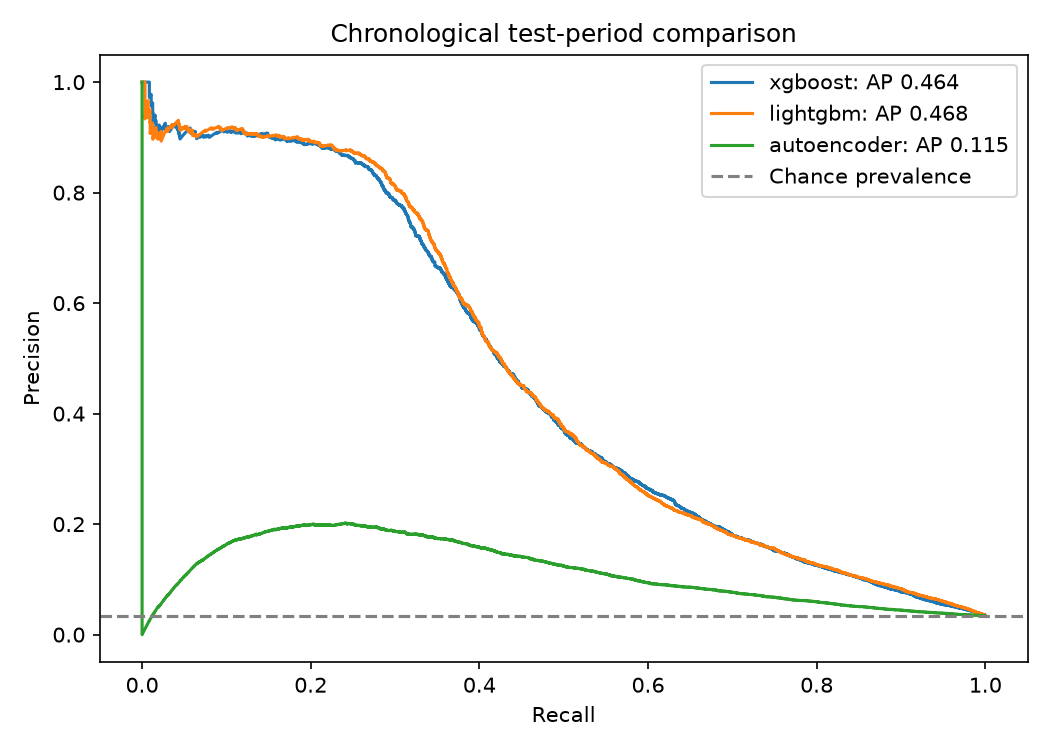

In [2]:
if RUN_TRAINING:
    tree_scores = pd.read_csv(DEFAULT_OUT / "test_scores.csv")
    ae_scores = pd.read_csv(AE_OUT / "test_scores.csv")
    scores = tree_scores.merge(ae_scores, on="TransactionID", validate="one_to_one", suffixes=("", "_ae"))
    assert len(scores) == len(tree_scores) == len(ae_scores)
    np.testing.assert_array_equal(scores.y_true, scores.y_true_ae)
    fig, ax = plt.subplots(figsize=(7, 5))
    for name in ["xgboost", "lightgbm", "autoencoder"]:
        precision, recall, _ = precision_recall_curve(scores.y_true, scores[name])
        ap = average_precision_score(scores.y_true, scores[name])
        ax.plot(recall, precision, label=f"{name}: AP {ap:.3f}")
    ax.axhline(scores.y_true.mean(), color="gray", linestyle="--", label="Chance prevalence")
    ax.set(xlabel="Recall", ylabel="Precision", title="Chronological test-period comparison")
    ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["model_comparison.png"])))

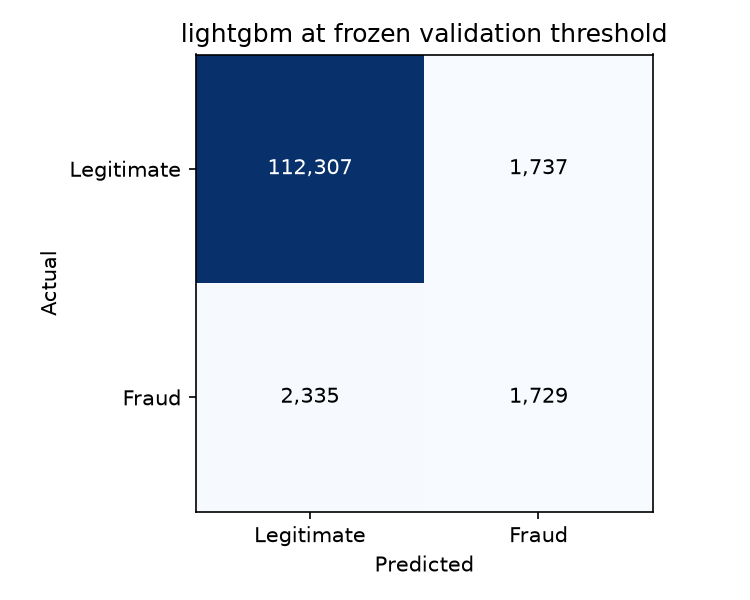

In [3]:
if RUN_TRAINING:
    display(Image(filename=str(DEFAULT_OUT / "confusion_matrix.png")))
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["confusion_matrix.png"])))

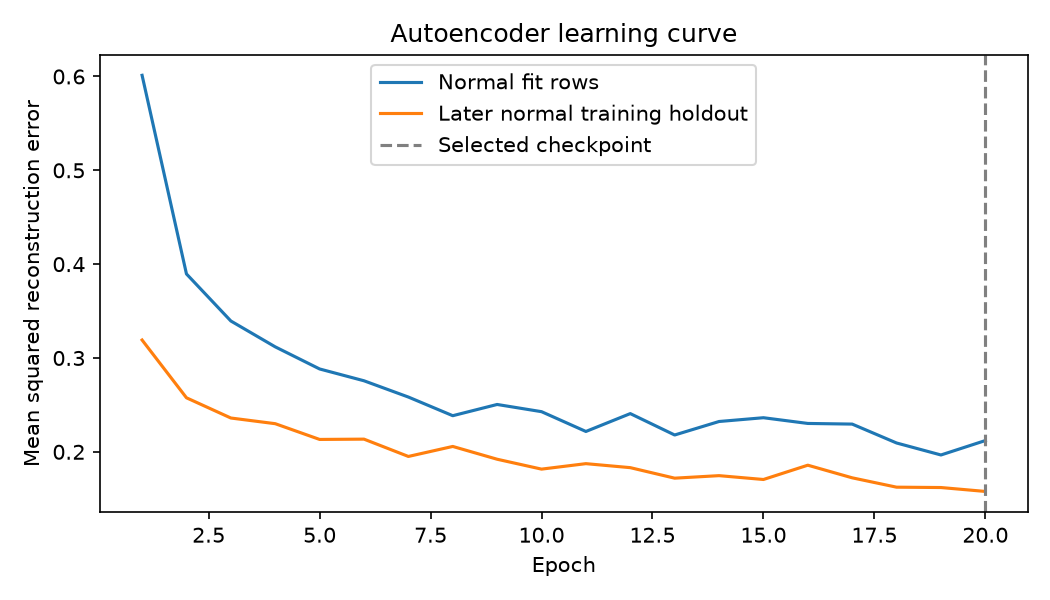

In [4]:
if RUN_TRAINING:
    history = pd.read_csv(AE_OUT / "training_history.csv")
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(history.epoch, history.train_mse, label="Normal fit rows")
    ax.plot(history.epoch, history.holdout_mse, label="Later normal holdout")
    ax.set(xlabel="Epoch", ylabel="Mean reconstruction error", title="Autoencoder learning curve")
    ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["autoencoder_training.png"])))

## 6. Validation-selected model improvements

Four candidates were specified before fitting. Test transactions were excluded from candidate training and selection. The changes tested native categorical handling, a larger tree budget, imbalance weights, and training-only card/email/amount summaries. Unknown categories map to missing; unknown group counts map to zero. Group amount means and standard deviations are learned without labels from training records only.

The selected configuration is **native_1200_unweighted**, with **0.6166 validation average precision**, versus **0.5560** for the initial LightGBM. The selected checkpoint used **1182 boosting rounds**.

Its threshold was frozen on validation before follow-up test scoring. On the existing chronological test period, it achieved **0.4937 average precision**, **0.8742 ROC-AUC**, **62.3% precision**, and **41.2% recall**.

**Evaluation history:** This is an iterative follow-up on a test period whose initial results were already reported. Candidate selection used validation only, but the follow-up result is not a new independent test. The initial results remain visible as the baseline. No candidates were adjusted after looking at the follow-up test scores.

To reproduce this extension, complete the initial training and set `RUN_IMPROVEMENTS = True` below. Its outputs stay in a separate folder and existing policies are not overwritten.

In [ ]:
import lightgbm as lgb
IMPROVEMENT_OUT = ROOT / "output/notebook_run/improvements"
RUN_IMPROVEMENTS = False

def json_save(path,obj):
 Path(path).write_text(json.dumps(obj,indent=2,default=str)+'\n')

def raw_risk_features(raw, enriched):
 """Row-wise features only. No labels, outcome aggregates, or calendar assumptions."""
 x=raw.drop(columns=['isFraud','TransactionID','TransactionDT'],errors='ignore').copy()
 x['relative_hour']=(raw.TransactionDT//3600)%24
 x['log_amount']=np.log1p(raw.TransactionAmt.clip(lower=0))
 x['amount_cents']=np.round(raw.TransactionAmt*100)%100
 if enriched:
  x['missing_field_count']=x.isna().sum(axis=1)
  x['has_identity']=raw.id_01.notna().astype('int8')
  known=raw.P_emaildomain.notna() & raw.R_emaildomain.notna()
  x['same_email_domain']=(raw.P_emaildomain==raw.R_emaildomain).where(known).astype(float)
  x['card_address']=raw.card1.astype(str)+'_'+raw.addr1.astype(str)
  x['card_address_email']=x.card_address+'_'+raw.P_emaildomain.astype('string').fillna('__missing__')
  for c in ['P_emaildomain','R_emaildomain']:
   x[c+'_provider']=raw[c].astype('string').str.split('.').str[0]
   x[c+'_suffix']=raw[c].astype('string').str.rsplit('.',n=1).str[-1]
 return x.replace([np.inf,-np.inf],np.nan)

def fit_native_features(train,enriched):
 x=raw_risk_features(train,enriched)
 state={'enriched':enriched,'aggregates':{},'categories':{},'columns':None}
 if enriched:
  for col in ['card1','card2','card_address','card_address_email','P_emaildomain']:
   key=x[col].astype("string").fillna("__missing__")
   stats=pd.DataFrame({'key':key,'amount':train.TransactionAmt.to_numpy()}).groupby('key').amount.agg(['count','mean','std'])
   state['aggregates'][col]=stats.to_dict()
  x=add_train_aggregates(x,state)
 identifiers=['card1','card2','card3','card5','addr1','addr2']
 category_cols=sorted(set(x.select_dtypes(exclude=np.number).columns.tolist()+identifiers))
 for col in category_cols:
  x[col]=x[col].astype("string").fillna("__missing__")
  values=x[col].unique().tolist();state['categories'][col]=values
  x[col]=pd.Categorical(x[col],categories=values)
 state['columns']=x.columns.tolist()
 return x,state

def add_train_aggregates(x,state):
 for col,mappings in state['aggregates'].items():
  key=x[col].astype("string").fillna("__missing__")
  x[col+'_train_count']=key.map(mappings['count']).fillna(0).astype(float)
  avg=key.map(mappings['mean'])
  std=key.map(mappings['std'])
  x[col+'_amount_ratio']=x.TransactionAmt/avg.replace(0,np.nan)
  x[col+'_amount_z']=(x.TransactionAmt-avg)/std.replace(0,np.nan)
 return x.replace([np.inf,-np.inf],np.nan)

def transform_native_features(raw,state):
 x=raw_risk_features(raw,state['enriched'])
 if state['enriched']:x=add_train_aggregates(x,state)
 for col,values in state['categories'].items():
  values_to_encode=x[col].astype("string").fillna("__missing__")
  x[col]=pd.Categorical(values_to_encode.where(values_to_encode.isin(values)),categories=values)
 return x[state['columns']]

def choose_threshold(y,scores):
 p,r,t=precision_recall_curve(y,scores)
 f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-15)
 return float(t[np.argmax(f)])

def risk_metrics(y,scores,threshold):
 predicted=scores>=threshold
 tn,fp,fn,tp=confusion_matrix(y,predicted,labels=[0,1]).ravel()
 return {'average_precision':float(average_precision_score(y,scores)),'roc_auc':float(roc_auc_score(y,scores)),
 'precision':float(precision_score(y,predicted,zero_division=0)),'recall':float(recall_score(y,predicted,zero_division=0)),
 'f1':float(f1_score(y,predicted,zero_division=0)),'threshold':threshold,'tp':int(tp),'fp':int(fp),'tn':int(tn),'fn':int(fn)}

def train_study():
 if (IMPROVEMENT_OUT/'study_plan.json').exists():raise FileExistsError('Do not overwrite an existing study')
 IMPROVEMENT_OUT.mkdir(parents=True,exist_ok=True)
 configs=[
  {'name':'native_250_weighted','enriched':False,'trees':250,'leaves':31,'depth':6,'weight':'balanced'},
  {'name':'native_1200_unweighted','enriched':False,'trees':1200,'leaves':63,'depth':-1,'weight':None},
  {'name':'entity_1200_unweighted','enriched':True,'trees':1200,'leaves':63,'depth':-1,'weight':None},
  {'name':'entity_1200_sqrt_weight','enriched':True,'trees':1200,'leaves':63,'depth':-1,'weight':'sqrt'},
 ]
 manifest=json.loads((DEFAULT_OUT / 'split_manifest.json').read_text())
 json_save(IMPROVEMENT_OUT/'study_plan.json',{'created_at_utc':datetime.now(timezone.utc).isoformat(),
 'candidates':configs,'selection_metric':'validation average precision','seed':SEED,
 'test_policy':'Existing reported test set. Excluded from candidate tuning; selected candidate evaluated once as follow-up.',
 'maximum_candidates':4,'early_stopping_metric':'average_precision','early_stopping_rounds':80,
 'split_manifest':manifest})
 print('Plan frozen: four validation candidates. Loading only training/validation transactions...',flush=True)
 # Read only rows up to the validation boundary; no test labels enter this study.
 chunks=[]
 for chunk in pd.read_csv(ROOT/'data/train_transaction.csv',chunksize=100000):
  part=chunk.loc[chunk.TransactionDT<=manifest['validation']['last_time']]
  if len(part):chunks.append(part)
 transaction=pd.concat(chunks,ignore_index=True);del chunks
 identity=pd.read_csv(ROOT/'data/train_identity.csv')
 frame=transaction.merge(identity,on='TransactionID',how='left',validate='one_to_one');del transaction,identity
 train=frame.loc[frame.TransactionDT<=manifest['train']['last_time']].sort_values(['TransactionDT','TransactionID']).reset_index(drop=True)
 valid=frame.loc[frame.TransactionDT>manifest['train']['last_time']].sort_values(['TransactionDT','TransactionID']).reset_index(drop=True)
 del frame
 assert len(train)==manifest['train']['rows'] and len(valid)==manifest['validation']['rows']
 y=train.isFraud.to_numpy();yv=valid.isFraud.to_numpy()
 results=[];current=None;best=-1
 for config in configs:
  start=time.perf_counter()
  if current!=config['enriched']:
   if current is not None:del X,Xv,state
   X,state=fit_native_features(train,config['enriched'])
   Xv=transform_native_features(valid,state)
   current=config['enriched']
  weight=config['weight']
  class_weight='balanced' if weight=='balanced' else None
  scale_pos_weight=np.sqrt((y==0).sum()/(y==1).sum()) if weight=='sqrt' else 1.
  model=lgb.LGBMClassifier(n_estimators=config['trees'],num_leaves=config['leaves'],max_depth=config['depth'],
    learning_rate=.04,min_child_samples=40,colsample_bytree=.85,subsample=.85,subsample_freq=1,
    reg_lambda=2.,cat_smooth=20.,class_weight=class_weight,scale_pos_weight=scale_pos_weight,
    metric='average_precision',random_state=SEED,n_jobs=4,verbosity=-1)
  print('Training',config['name'],'features',X.shape[1],flush=True)
  model.fit(X,y,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(80,first_metric_only=True,verbose=False)])
  scores=model.predict_proba(Xv)[:,1]
  row={'name':config['name'],'best_iteration':int(model.best_iteration_),'fit_seconds':time.perf_counter()-start,
    **risk_metrics(yv,scores,choose_threshold(yv,scores))}
  results.append(row);pd.DataFrame(results).to_csv(IMPROVEMENT_OUT/'validation_candidates.csv',index=False)
  print(row,flush=True)
  if row['average_precision']>best:
   best=row['average_precision']
   model.booster_.save_model(str(IMPROVEMENT_OUT/'selected_model.txt'))
   # Plain mappings plus native Booster file avoid notebook-specific class pickles.
   import joblib
   joblib.dump(state,IMPROVEMENT_OUT/'selected_feature_state.joblib')
   pd.DataFrame({'TransactionID':valid.TransactionID,'y_true':yv,'score':scores}).to_csv(IMPROVEMENT_OUT/'selected_validation_scores.csv',index=False)
   json_save(IMPROVEMENT_OUT/'selected_config.json',config)
 chosen=max(results,key=lambda x:x['average_precision'])
 baseline=json.loads((DEFAULT_OUT / 'decision_policy.json').read_text())
 baseline_validation=pd.read_csv(DEFAULT_OUT / 'validation_metrics.csv')
 baseline_ap=float(baseline_validation.loc[baseline_validation.model==baseline['primary_model'],'average_precision'].iloc[0])
 json_save(IMPROVEMENT_OUT/'decision_policy.json',{'frozen_at_utc':datetime.now(timezone.utc).isoformat(),
  'selected_validation':chosen,'baseline_validation_ap':baseline_ap,
  'selection':'maximum validation average precision among four planned candidates',
  'threshold':chosen['threshold'],'test_previously_reported':True,
  'baseline_policy':baseline,'evaluate_test':chosen['average_precision']>baseline_ap})
 print('Selected policy frozen:',chosen,flush=True)

def evaluate_selected():
 import joblib
 policy=json.loads((IMPROVEMENT_OUT/'decision_policy.json').read_text())
 if not policy['evaluate_test']:
  print('No validation improvement; keep the existing model.');return
 if (IMPROVEMENT_OUT/'test_metrics.json').exists():raise FileExistsError('Selected test evaluation already exists')
 manifest=json.loads((IMPROVEMENT_OUT/'study_plan.json').read_text())['split_manifest']
 parts=[]
 for chunk in pd.read_csv(ROOT/'data/train_transaction.csv',chunksize=100000):
  part=chunk.loc[chunk.TransactionDT>=manifest['test']['first_time']]
  if len(part):parts.append(part)
 transaction=pd.concat(parts,ignore_index=True)
 identity=pd.read_csv(ROOT/'data/train_identity.csv')
 raw=transaction.merge(identity,on='TransactionID',how='left',validate='one_to_one').sort_values(['TransactionDT','TransactionID']).reset_index(drop=True)
 assert len(raw)==manifest['test']['rows']
 state=joblib.load(IMPROVEMENT_OUT/'selected_feature_state.joblib')
 model=lgb.Booster(model_file=str(IMPROVEMENT_OUT/'selected_model.txt'))
 scores=model.predict(transform_native_features(raw.drop(columns='isFraud'),state),num_threads=4)
 result=risk_metrics(raw.isFraud.to_numpy(),scores,policy['threshold'])
 json_save(IMPROVEMENT_OUT/'test_metrics.json',{'evaluated_at_utc':datetime.now(timezone.utc).isoformat(),
  'selected_name':policy['selected_validation']['name'],'test_previously_reported':True,**result})
 pd.DataFrame({'TransactionID':raw.TransactionID,'y_true':raw.isFraud,'score':scores}).to_csv(IMPROVEMENT_OUT/'selected_test_scores.csv',index=False)
 print('FOLLOW-UP TEST RESULT',result,flush=True)

In [6]:
if RUN_TRAINING and RUN_IMPROVEMENTS:
    train_study()
    evaluate_selected()
    display(pd.read_csv(IMPROVEMENT_OUT / "validation_candidates.csv").round(4))
    print(json.dumps(json.loads((IMPROVEMENT_OUT / "test_metrics.json").read_text()), indent=2))
else:
    display(pd.DataFrame(REPORTED["improvement_candidates"])[["name", "best_iteration", "average_precision", "roc_auc", "precision", "recall"]].round(4))
    print("Reported follow-up test result:", REPORTED["improved_test"])


name,best_iteration,average_precision,roc_auc,precision,recall
native_250_weighted,250,0.5437,0.9095,0.5945,0.4830
native_1200_unweighted,1182,0.6166,0.9138,0.7435,0.5231
entity_1200_unweighted,1200,0.6147,0.9136,0.7351,0.5255
entity_1200_sqrt_weight,1200,0.6079,0.9138,0.7039,0.5300


{
  "evaluated_at_utc": "2026-10-21T04:00:59.355391+00:00",
  "selected_name": "native_1200_unweighted",
  "test_previously_reported": true,
  "average_precision": 0.4936832109567741,
  "roc_auc": 0.8741932592945892,
  "precision": 0.6228167967298402,
  "recall": 0.4124015748031496,
  "f1": 0.49622501850481127,
  "threshold": 0.18151573283012326,
  "tp": 1676,
  "fp": 1015,
  "tn": 113029,
  "fn": 2388
}


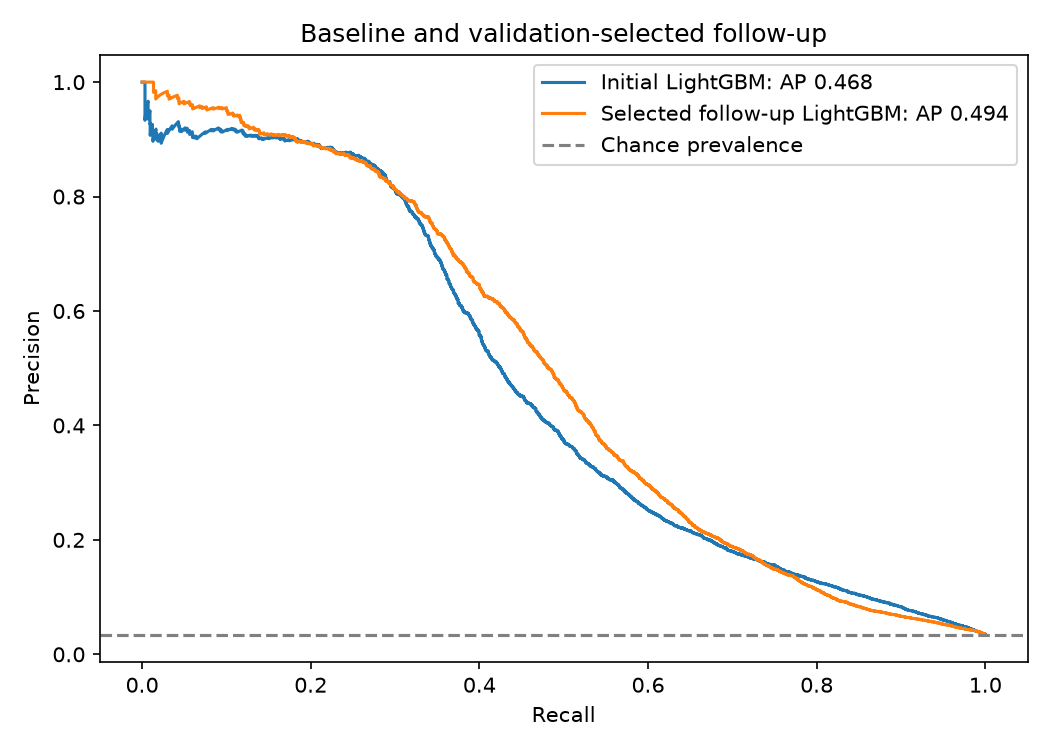

In [7]:
if RUN_TRAINING and RUN_IMPROVEMENTS:
    base_scores = pd.read_csv(DEFAULT_OUT / "test_scores.csv")
    followup_scores = pd.read_csv(IMPROVEMENT_OUT / "selected_test_scores.csv")
    aligned = base_scores.merge(followup_scores, on="TransactionID", validate="one_to_one", suffixes=("", "_new"))
    assert len(aligned) == len(base_scores) == len(followup_scores)
    np.testing.assert_array_equal(aligned.y_true, aligned.y_true_new)
    fig, ax = plt.subplots(figsize=(7, 5))
    for label, column in [("Initial LightGBM", "lightgbm"), ("Selected follow-up", "score")]:
        p, r, _ = precision_recall_curve(aligned.y_true, aligned[column])
        ap = average_precision_score(aligned.y_true, aligned[column])
        ax.plot(r, p, label=f"{label}: AP {ap:.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", title="Baseline and follow-up")
    ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["improvement_comparison.png"])))


In [ ]:
def score_improved_records(raw, artifact_dir=IMPROVEMENT_OUT):
    if not raw.TransactionID.is_unique:
        raise ValueError("TransactionID must be unique")
    feature_state = joblib.load(artifact_dir / "selected_feature_state.joblib")
    detector = lgb.Booster(model_file=str(artifact_dir / "selected_model.txt"))
    frozen = json.loads((artifact_dir / "decision_policy.json").read_text())
    risk = detector.predict(transform_native_features(raw, feature_state), num_threads=4)
    return pd.DataFrame({"TransactionID": raw.TransactionID.to_numpy(),
                         "fraud_score": risk, "alert": risk >= frozen["threshold"]})


### Selected follow-up model explanations

Native LightGBM TreeSHAP contributions are computed on 500 uniformly sampled validation rows. The chart summarizes mean absolute contributions on the raw model-output scale. Contributions plus the bias term were checked to sum to the raw model score.

The beeswarm in Section 8 explains the initial model; this chart explains the selected follow-up. Neither explanation establishes causality or the hidden meanings of anonymous features.

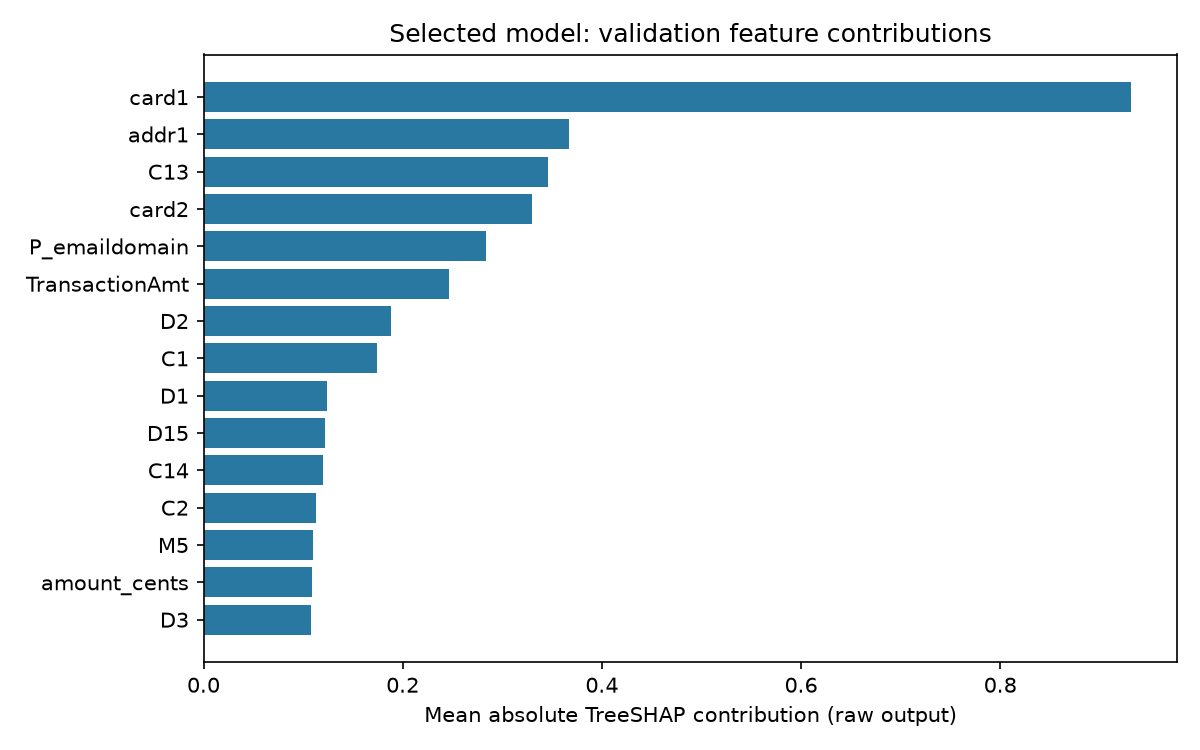

In [8]:
if RUN_TRAINING and RUN_IMPROVEMENTS:
    frozen = json.loads((IMPROVEMENT_OUT / "study_plan.json").read_text())
    boundaries = frozen["split_manifest"]["validation"]
    parts = []
    for chunk in pd.read_csv(ROOT / "data/train_transaction.csv", chunksize=100000):
        part = chunk.loc[(chunk.TransactionDT >= boundaries["first_time"]) &
                         (chunk.TransactionDT <= boundaries["last_time"])]
        if len(part):
            parts.append(part)
    sample = pd.concat(parts, ignore_index=True).sample(n=500, random_state=42)
    identity = pd.read_csv(ROOT / "data/train_identity.csv")
    sample = sample.merge(identity, on="TransactionID", how="left", validate="one_to_one")
    del identity, parts
    feature_state = joblib.load(IMPROVEMENT_OUT / "selected_feature_state.joblib")
    detector = lgb.Booster(model_file=str(IMPROVEMENT_OUT / "selected_model.txt"))
    sample_features = transform_native_features(sample.drop(columns="isFraud"), feature_state)
    contributions = detector.predict(sample_features, pred_contrib=True, num_threads=4)
    np.testing.assert_allclose(contributions.sum(axis=1),
        detector.predict(sample_features, raw_score=True, num_threads=4), rtol=1e-5, atol=1e-6)
    importance = pd.DataFrame({"feature": detector.feature_name(),
        "mean_absolute_shap": np.abs(contributions[:, :-1]).mean(axis=0)})
    top = importance.nlargest(15, "mean_absolute_shap").iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(top.feature, top.mean_absolute_shap)
    ax.set(xlabel="Mean absolute TreeSHAP contribution (raw output)",
           title="Selected model: validation feature contributions")
    fig.tight_layout(); display(fig); plt.close(fig)
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["selected_shap.png"])))
    print("Saved-run checks:", REPORTED["improvement_verification"])


## 7. Controlled reference comparison and temporal/entity features

This study adapts the reference repository's 500-tree XGBoost and LightGBM settings to the same chronological training and validation periods as our models. It is not an exact reproduction: frequency maps and the 50%-missingness schema fit on training only, early stopping and thresholds use validation, and execution uses CPU. Relative-time phases are not interpreted as actual weekdays or local clock hours. The reference snapshot is `cc44401d9640072a740dd353a93713743903f31c`.

Two further candidates add reference-adjusted time deltas and label-free group summaries. A proxy group key combines card/address information with `floor(TransactionDT / 86400 - D1)`. The key itself is excluded from model inputs; training-fitted counts, means, standard deviations, and distinct-value counts provide its information. It is a grouping hypothesis, not a verified customer identity. Unknown groups retain missing aggregates rather than borrowing information from validation or test records.

Feature ideas are adapted from [the winning team's technical explanation](https://developer.nvidia.com/blog/leveraging-machine-learning-to-detect-fraud-tips-to-developing-a-winning-kaggle-solution/). Model settings are compared with [the reference project](https://github.com/neshatsh/Financial-Fraud-Detection-System/tree/cc44401d9640072a740dd353a93713743903f31c).

Four model fits and three fixed blend weights were planned before training. Selection maximizes validation average precision; each threshold maximizes validation F1. The selected candidate is **blend_0.25** with **0.6596 validation average precision**.

The selected candidate achieved **0.5517 average precision**, **0.9017 ROC-AUC**, **68.3% precision**, and **46.0% recall** on the existing test period. It caught **1,871 fraud cases** with **870 false alarms**.

**Evaluation history:** This is another validation-selected follow-up on a test period whose earlier results were already reported. It is not a fresh independent test. All predefined model results are shown; test performance did not select the reported winner. Earlier stages remain visible as the experimental history.

Set `RUN_CONTROLLED = True` below after reproducing the initial baseline to rerun this study in a separate output directory.

In [ ]:
import xgboost as xgb
CONTROLLED_OUT = ROOT / "output/notebook_run/controlled"
RUN_CONTROLLED = False
CONTROLLED_FEATURE_SOURCE = "https://developer.nvidia.com/blog/leveraging-machine-learning-to-detect-fraud-tips-to-developing-a-winning-kaggle-solution/"

def write_result(path,obj):Path(path).write_text(json.dumps(obj,indent=2,default=str)+'\n')

def threshold_for_f1(y,s):
 p,r,t=precision_recall_curve(y,s);f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-15)
 return float(t[np.argmax(f)])

def report_metrics(y,s,t):
 pred=s>=t;tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
 return dict(average_precision=float(average_precision_score(y,s)),roc_auc=float(roc_auc_score(y,s)),
  precision=float(precision_score(y,pred,zero_division=0)),recall=float(recall_score(y,pred,zero_division=0)),
  f1=float(f1_score(y,pred,zero_division=0)),accuracy=float((tp+tn)/len(y)),threshold=t,
  tp=int(tp),fp=int(fp),fn=int(fn),tn=int(tn))

def load_labeled_period(manifest,split):
 parts=[]
 lo=manifest[split]['first_time'];hi=manifest[split]['last_time']
 for chunk in pd.read_csv(ROOT/'data/train_transaction.csv',chunksize=100000):
  part=chunk.loc[(chunk.TransactionDT>=lo)&(chunk.TransactionDT<=hi)]
  if len(part):parts.append(part)
 transaction=pd.concat(parts,ignore_index=True)
 identity=pd.read_csv(ROOT/'data/train_identity.csv')
 frame=transaction.merge(identity,on='TransactionID',how='left',validate='one_to_one')
 return frame.sort_values(['TransactionDT','TransactionID']).reset_index(drop=True)

def reference_rows(raw,maps):
 x=raw.drop(columns=['TransactionID','isFraud','TransactionDT','P_emaildomain','R_emaildomain'],errors='ignore').copy()
 hour=(raw.TransactionDT//3600)%24;phase=(raw.TransactionDT//86400)%7
 x['hour']=hour;x['relative_day_phase']=phase
 x['night_phase']=((hour>=22)|(hour<=6)).astype(int);x['weekend_phase']=(phase>=5).astype(int)
 x['log_amount']=np.log1p(raw.TransactionAmt)
 x['amount_cents']=(raw.TransactionAmt*100%100).round(0)
 x['is_round_amount']=(x.amount_cents==0).astype(int)
 for c in ['card1','card2']:x[c+'_freq']=raw[c].map(maps[c]).astype(float)
 x['P_email_domain']=raw.P_emaildomain.fillna('unknown')
 x['R_email_domain']=raw.R_emaildomain.fillna('unknown')
 x['same_email']=(x.P_email_domain==x.R_email_domain).astype(int)
 x['has_identity']=raw.id_01.notna().astype(int)
 return x

def fit_reference(train):
 state={'maps':{c:train[c].value_counts().to_dict() for c in ['card1','card2']}}
 x=reference_rows(train,state['maps'])
 state['columns']=x.columns[x.isna().mean()<=.5].tolist();x=x[state['columns']]
 nums=x.select_dtypes(include=np.number).columns.tolist();cats=[c for c in x if c not in nums]
 for c in cats:x[c]=x[c].astype(object).where(x[c].notna(),np.nan)
 prep=ColumnTransformer([
  ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),nums),
  ('cat',Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='missing')),
   ('encode',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))]),cats)])
 state['categorical']=cats;state['preprocessor']=prep
 return prep.fit_transform(x).astype(np.float32),state

def transform_reference(raw,state):
 x=reference_rows(raw,state['maps'])[state['columns']]
 for c in state['categorical']:x[c]=x[c].astype(object).where(x[c].notna(),np.nan)
 return state['preprocessor'].transform(x).astype(np.float32)

def temporal_entity_rows(raw):
 x=raw.drop(columns=['TransactionID','isFraud','TransactionDT'],errors='ignore').copy()
 day=raw.TransactionDT/86400.
 x['relative_hour']=(raw.TransactionDT//3600)%24
 x['log_amount']=np.log1p(raw.TransactionAmt.clip(lower=0))
 x['amount_cents']=np.round(raw.TransactionAmt*100)%100
 x['missing_field_count']=x.isna().sum(axis=1)
 # Row-wise reference adjustment, not a claim of actual calendar dates.
 for c in ['D1','D2','D4','D6','D7','D8','D10','D11','D12','D13','D14','D15']:
  x[c+'_reference_adjusted']=day-raw[c]
 card=raw.card1.astype('string').fillna('__missing__');addr=raw.addr1.astype('string').fillna('__missing__')
 x['card_address']=card+'_'+addr
 anchor=np.floor(day-raw.D1).astype('string').fillna('__missing__')
 x['_entity_key']=x.card_address+'_'+anchor
 known=raw.P_emaildomain.notna()&raw.R_emaildomain.notna()
 x['same_email_domain']=(raw.P_emaildomain==raw.R_emaildomain).where(known).astype(float)
 return x.replace([np.inf,-np.inf],np.nan)

def add_entity_statistics(x,state):
 for group,fields in state['aggregates'].items():
  key=x[group].astype('string').fillna('__missing__')
  for name,mapping in fields.items():x[group+'__'+name]=key.map(mapping).astype(float)
 return x.drop(columns='_entity_key').replace([np.inf,-np.inf],np.nan)

def fit_temporal_entity(train):
 x=temporal_entity_rows(train)
 state={'aggregates':{},'categories':{}}
 measures=['TransactionAmt','D4','D9','D10','D15','C1','C2','C13','C14']
 for group in ['_entity_key','card_address']:
  keys=x[group].astype('string').fillna('__missing__')
  state['aggregates'][group]={'count':keys.value_counts().to_dict()}
  for col in measures:
   stat=x[col].groupby(keys).agg(['mean','std'])
   for func in ['mean','std']:state['aggregates'][group][col+'_'+func]=stat[func].to_dict()
  for col in ['P_emaildomain','dist1','C13']:
   state['aggregates'][group][col+'_distinct']=x[col].groupby(keys).nunique().to_dict()
 x=add_entity_statistics(x,state)
 cats=sorted(set(x.select_dtypes(exclude=np.number).columns.tolist()+['card1','card2','card3','card5','addr1','addr2']))
 for col in cats:
  value=x[col].astype('string').fillna('__missing__')
  state['categories'][col]=value.unique().tolist()
  x[col]=pd.Categorical(value,categories=state['categories'][col])
 state['columns']=x.columns.tolist()
 return x,state

def transform_temporal_entity(raw,state):
 x=add_entity_statistics(temporal_entity_rows(raw),state)
 for col,values in state['categories'].items():
  value=x[col].astype('string').fillna('__missing__')
  x[col]=pd.Categorical(value.where(value.isin(values)),categories=values)
 return x[state['columns']]

def numeric_tree_matrix(frame):
 return np.column_stack([frame[c].cat.codes.to_numpy(dtype=np.float32) if isinstance(frame[c].dtype,pd.CategoricalDtype)
  else frame[c].to_numpy(dtype=np.float32,na_value=np.nan) for c in frame])

def train_controlled():
 if (CONTROLLED_OUT/'plan.json').exists():raise FileExistsError('An existing controlled study must not be overwritten')
 CONTROLLED_OUT.mkdir(parents=True,exist_ok=True)
 manifest=json.loads((DEFAULT_OUT / 'split_manifest.json').read_text())
 plan={'created_at_utc':datetime.now(timezone.utc).isoformat(),'seed':SEED,'split_manifest':manifest,
 'source':CONTROLLED_FEATURE_SOURCE,'reference_repository':'https://github.com/neshatsh/Financial-Fraud-Detection-System',
 'adaptations':['CPU instead of CUDA','chronological 60/20/20 split','validation early stopping and thresholds',
  'training-only frequency maps and missingness schema','relative calendar phases carry no actual weekday semantics'],
 'models':['reference_xgboost_500','reference_lightgbm_500','temporal_entity_lightgbm','temporal_entity_xgboost'],
 'temporal_lgb':{'trees':1800,'leaves':63,'learning_rate':.035,'min_child_samples':40},
 'temporal_xgb':{'trees':1500,'depth':8,'learning_rate':.035,'min_child_weight':10},
 'blend_lgb_weights':[.25,.5,.75],'selection_metric':'validation average precision',
 'threshold_policy':'maximum validation F1','test_previously_reported':True,
 'test_policy':'Evaluate predefined models and validation-selected candidate once after policy freezing'}
 write_result(CONTROLLED_OUT/'plan.json',plan)
 print('Plan frozen: two reference-settings models, two temporal/entity models, three fixed blends.',flush=True)
 train=load_labeled_period(manifest,'train');valid=load_labeled_period(manifest,'validation')
 y=train.isFraud.to_numpy();yv=valid.isFraud.to_numpy();ratio=float((y==0).sum()/(y==1).sum())
 X,state=fit_reference(train);Xv=transform_reference(valid,state)
 joblib.dump(state,CONTROLLED_OUT/'reference_state.joblib')
 configs={
 'reference_xgboost_500':xgb.XGBClassifier(n_estimators=500,max_depth=6,learning_rate=.05,
  subsample=.8,colsample_bytree=.8,scale_pos_weight=ratio,eval_metric='aucpr',early_stopping_rounds=20,
  tree_method='hist',random_state=42,n_jobs=4),
 'reference_lightgbm_500':lgb.LGBMClassifier(n_estimators=500,max_depth=6,learning_rate=.05,
  subsample=.8,colsample_bytree=.8,class_weight='balanced',random_state=42,n_jobs=4,verbosity=-1),
 }
 results=[];predictions=pd.DataFrame({'TransactionID':valid.TransactionID,'y_true':yv})
 def record(name,model,scores,elapsed,best):
  result={'name':name,'fit_seconds':elapsed,'best_iteration':int(best),**report_metrics(yv,scores,threshold_for_f1(yv,scores))}
  results.append(result);predictions[name]=scores
  pd.DataFrame(results).to_csv(CONTROLLED_OUT/'validation_metrics.csv',index=False)
  predictions.to_csv(CONTROLLED_OUT/'validation_scores.csv',index=False)
  print(result,flush=True)
 for name,model in configs.items():
  t=time.perf_counter();print('Training',name,'features',X.shape[1],flush=True)
  if name.startswith('reference_xgb'):
   model.fit(X,y,eval_set=[(Xv,yv)],verbose=False);model.save_model(CONTROLLED_OUT/(name+'.ubj'));best=model.best_iteration+1
  else:
   model.fit(X,y,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(20,verbose=False)])
   model.booster_.save_model(str(CONTROLLED_OUT/(name+'.txt')));best=model.best_iteration_
  record(name,model,model.predict_proba(Xv)[:,1],time.perf_counter()-t,best)
 del X,Xv,configs,model,state
 X,state=fit_temporal_entity(train);Xv=transform_temporal_entity(valid,state)
 joblib.dump(state,CONTROLLED_OUT/'temporal_entity_state.joblib')
 print('Temporal/entity input features:',X.shape[1],flush=True)
 model=lgb.LGBMClassifier(n_estimators=1800,num_leaves=63,max_depth=-1,learning_rate=.035,
  min_child_samples=40,colsample_bytree=.75,subsample=.85,subsample_freq=1,reg_lambda=3.,
  cat_smooth=20,metric='average_precision',random_state=42,n_jobs=4,verbosity=-1)
 t=time.perf_counter();print('Training temporal_entity_lightgbm...',flush=True)
 model.fit(X,y,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(100,first_metric_only=True,verbose=False)])
 model.booster_.save_model(str(CONTROLLED_OUT/'temporal_entity_lightgbm.txt'))
 record('temporal_entity_lightgbm',model,model.predict_proba(Xv)[:,1],time.perf_counter()-t,model.best_iteration_)
 del model
 Xm=numeric_tree_matrix(X);Xvm=numeric_tree_matrix(Xv);del X,Xv
 model=xgb.XGBClassifier(n_estimators=1500,max_depth=8,learning_rate=.035,min_child_weight=10,
  subsample=.85,colsample_bytree=.6,reg_lambda=3.,max_bin=128,tree_method='hist',
  eval_metric='aucpr',early_stopping_rounds=100,random_state=42,n_jobs=4)
 t=time.perf_counter();print('Training temporal_entity_xgboost...',flush=True)
 model.fit(Xm,y,eval_set=[(Xvm,yv)],verbose=False);model.save_model(CONTROLLED_OUT/'temporal_entity_xgboost.ubj')
 record('temporal_entity_xgboost',model,model.predict_proba(Xvm)[:,1],time.perf_counter()-t,model.best_iteration+1)
 for weight in plan['blend_lgb_weights']:
  scores=weight*predictions.temporal_entity_lightgbm.to_numpy()+(1-weight)*predictions.temporal_entity_xgboost.to_numpy()
  record('blend_'+str(weight),None,scores,0,0)
 best=max(results,key=lambda r:r['average_precision'])
 write_result(CONTROLLED_OUT/'policy.json',{'frozen_at_utc':datetime.now(timezone.utc).isoformat(),'selected':best,
  'selection_metric':'validation average precision','threshold':best['threshold'],
  'thresholds':{r['name']:r['threshold'] for r in results},'test_previously_reported':True,
  'evaluate_names':plan['models']+([best['name']] if best['name'].startswith('blend_') else [])})
 print('POLICY FROZEN',best,flush=True)

def score_all_models(raw):
 ref=transform_reference(raw,joblib.load(CONTROLLED_OUT/'reference_state.joblib'))
 a=xgb.XGBClassifier();a.load_model(CONTROLLED_OUT/'reference_xgboost_500.ubj')
 scores={'reference_xgboost_500':a.predict_proba(ref)[:,1],
 'reference_lightgbm_500':lgb.Booster(model_file=str(CONTROLLED_OUT/'reference_lightgbm_500.txt')).predict(ref,num_threads=4)}
 del ref,a
 temporal=transform_temporal_entity(raw,joblib.load(CONTROLLED_OUT/'temporal_entity_state.joblib'))
 scores['temporal_entity_lightgbm']=lgb.Booster(model_file=str(CONTROLLED_OUT/'temporal_entity_lightgbm.txt')).predict(temporal,num_threads=4)
 b=xgb.XGBClassifier();b.load_model(CONTROLLED_OUT/'temporal_entity_xgboost.ubj')
 scores['temporal_entity_xgboost']=b.predict_proba(numeric_tree_matrix(temporal))[:,1]
 return scores

def evaluate_controlled():
 if (CONTROLLED_OUT/'test_metrics.csv').exists():raise FileExistsError('Existing controlled test evaluation')
 plan=json.loads((CONTROLLED_OUT/'plan.json').read_text());policy=json.loads((CONTROLLED_OUT/'policy.json').read_text())
 raw=load_labeled_period(plan['split_manifest'],'test')
 scores=score_all_models(raw.drop(columns='isFraud'))
 selected=policy['selected']['name']
 if selected.startswith('blend_'):
  weight=float(selected.split('_')[1]);scores[selected]=weight*scores['temporal_entity_lightgbm']+(1-weight)*scores['temporal_entity_xgboost']
 result=[];table=pd.DataFrame({'TransactionID':raw.TransactionID,'y_true':raw.isFraud})
 for name in policy['evaluate_names']:
  row={'name':name,**report_metrics(raw.isFraud.to_numpy(),scores[name],policy['thresholds'][name])}
  result.append(row);table[name]=scores[name];print('TEST',row,flush=True)
 pd.DataFrame(result).to_csv(CONTROLLED_OUT/'test_metrics.csv',index=False);table.to_csv(CONTROLLED_OUT/'test_scores.csv',index=False)
 write_result(CONTROLLED_OUT/'completion.json',{'evaluated_at_utc':datetime.now(timezone.utc).isoformat(),
  'selected_model':selected,'test_previously_reported':True,'n_test':len(raw)})

In [9]:
if RUN_TRAINING and RUN_CONTROLLED:
    train_controlled()
    evaluate_controlled()
    display(pd.read_csv(CONTROLLED_OUT / "validation_metrics.csv").round(4))
    display(pd.read_csv(CONTROLLED_OUT / "test_metrics.csv").round(4))
else:
    print("Validation candidates:")
    display(pd.DataFrame(REPORTED["controlled"]["validation"])[["name", "average_precision", "roc_auc", "precision", "recall", "f1"]].round(4))
    print("Predefined models and validation winner on the existing test period:")
    display(pd.DataFrame(REPORTED["controlled"]["test"])[["name", "average_precision", "roc_auc", "precision", "recall", "f1"]].round(4))


name,average_precision,roc_auc,precision,recall,f1
reference_xgboost_500,0.5596,0.9147,0.6244,0.4864,0.5469
reference_lightgbm_500,0.5556,0.9121,0.6704,0.4548,0.5419
temporal_entity_lightgbm,0.6280,0.9152,0.7051,0.5563,0.6219
temporal_entity_xgboost,0.6467,0.9307,0.7578,0.5394,0.6302
blend_0.25,0.6596,0.9353,0.7891,0.5404,0.6415
blend_0.5,0.6588,0.9342,0.7588,0.5608,0.6450
blend_0.75,0.6484,0.9300,0.7721,0.5409,0.6361


name,average_precision,roc_auc,precision,recall,f1
reference_xgboost_500,0.4559,0.8793,0.5341,0.4122,0.4653
reference_lightgbm_500,0.4546,0.8762,0.5845,0.3888,0.4670
temporal_entity_lightgbm,0.5233,0.8771,0.6167,0.4779,0.5385
temporal_entity_xgboost,0.5382,0.8993,0.6466,0.4668,0.5422
blend_0.25,0.5517,0.9017,0.6826,0.4604,0.5499


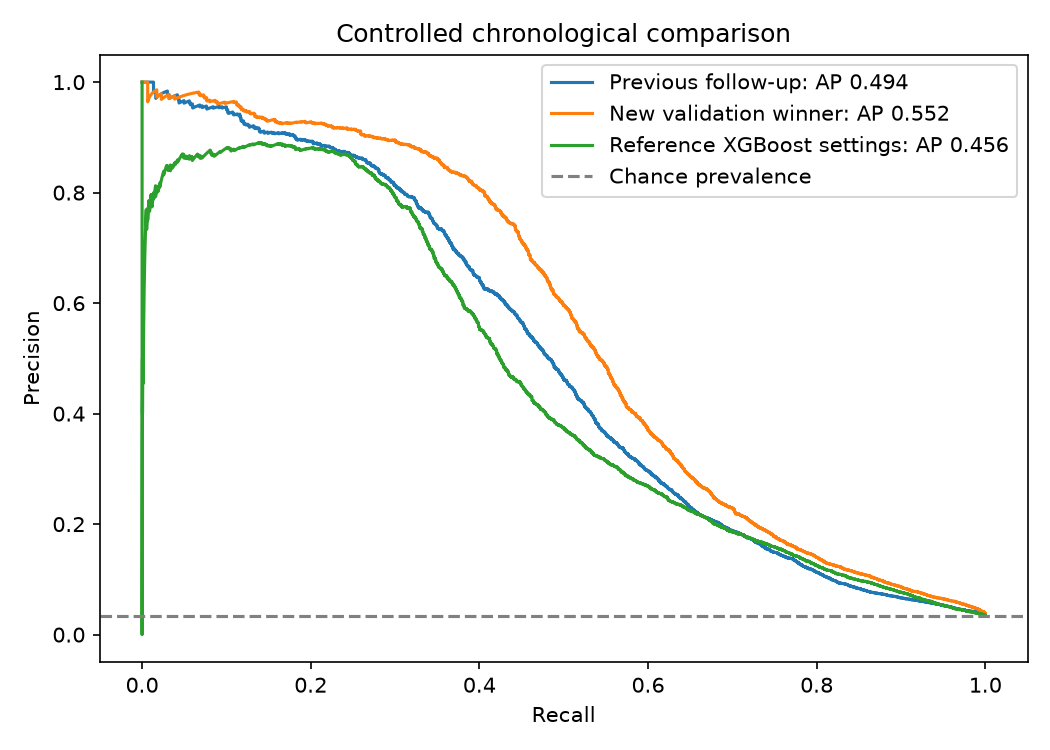

In [10]:
if RUN_TRAINING and RUN_CONTROLLED:
    controlled_scores = pd.read_csv(CONTROLLED_OUT / "test_scores.csv")
    frozen_policy = json.loads((CONTROLLED_OUT / "policy.json").read_text())
    fig, ax = plt.subplots(figsize=(7, 5))
    for name in frozen_policy["evaluate_names"]:
        p, r, _ = precision_recall_curve(controlled_scores.y_true, controlled_scores[name])
        ap = average_precision_score(controlled_scores.y_true, controlled_scores[name])
        ax.plot(r, p, label=f"{name}: AP {ap:.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", title="Controlled chronological comparison")
    ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["controlled_comparison.png"])))


In [ ]:
def score_controlled_records(raw, artifact_dir=CONTROLLED_OUT):
    if not raw.TransactionID.is_unique:
        raise ValueError("TransactionID must be unique")
    frozen = json.loads((artifact_dir / "policy.json").read_text())
    name = frozen["selected"]["name"]
    if name.startswith("reference_"):
        state = joblib.load(artifact_dir / "reference_state.joblib")
        matrix = transform_reference(raw, state)
        if "xgboost" in name:
            model = xgb.XGBClassifier(); model.load_model(artifact_dir / (name + ".ubj"))
            risk = model.predict_proba(matrix)[:, 1]
        else:
            risk = lgb.Booster(model_file=str(artifact_dir / (name + ".txt"))).predict(matrix, num_threads=4)
    else:
        matrix = transform_temporal_entity(raw, joblib.load(artifact_dir / "temporal_entity_state.joblib"))
        risk_lgb = risk_xgb = None
        if name == "temporal_entity_lightgbm" or name.startswith("blend_"):
            risk_lgb = lgb.Booster(model_file=str(artifact_dir / "temporal_entity_lightgbm.txt")).predict(matrix, num_threads=4)
        if name == "temporal_entity_xgboost" or name.startswith("blend_"):
            model = xgb.XGBClassifier(); model.load_model(artifact_dir / "temporal_entity_xgboost.ubj")
            risk_xgb = model.predict_proba(numeric_tree_matrix(matrix))[:, 1]
        if name.startswith("blend_"):
            weight = float(name.split("_")[1]); risk = weight * risk_lgb + (1 - weight) * risk_xgb
        else:
            risk = risk_lgb if risk_lgb is not None else risk_xgb
    return pd.DataFrame({"TransactionID": raw.TransactionID.to_numpy(), "fraud_score": risk,
                         "alert": risk >= frozen["threshold"]})


### Controlled-model explanation checks

Reloaded models reproduced every model/blend score on 800 sampled validation rows. Unknown-card and entirely missing email batches produced finite predictions.

The following TreeSHAP chart explains **temporal_entity_lightgbm**, a component of the selected blend when applicable. It uses a 500-row validation sample and raw component outputs. It does not explain the blended probability; averaging log-odds explanations would not establish that. Contribution additivity was checked against the component raw scores.

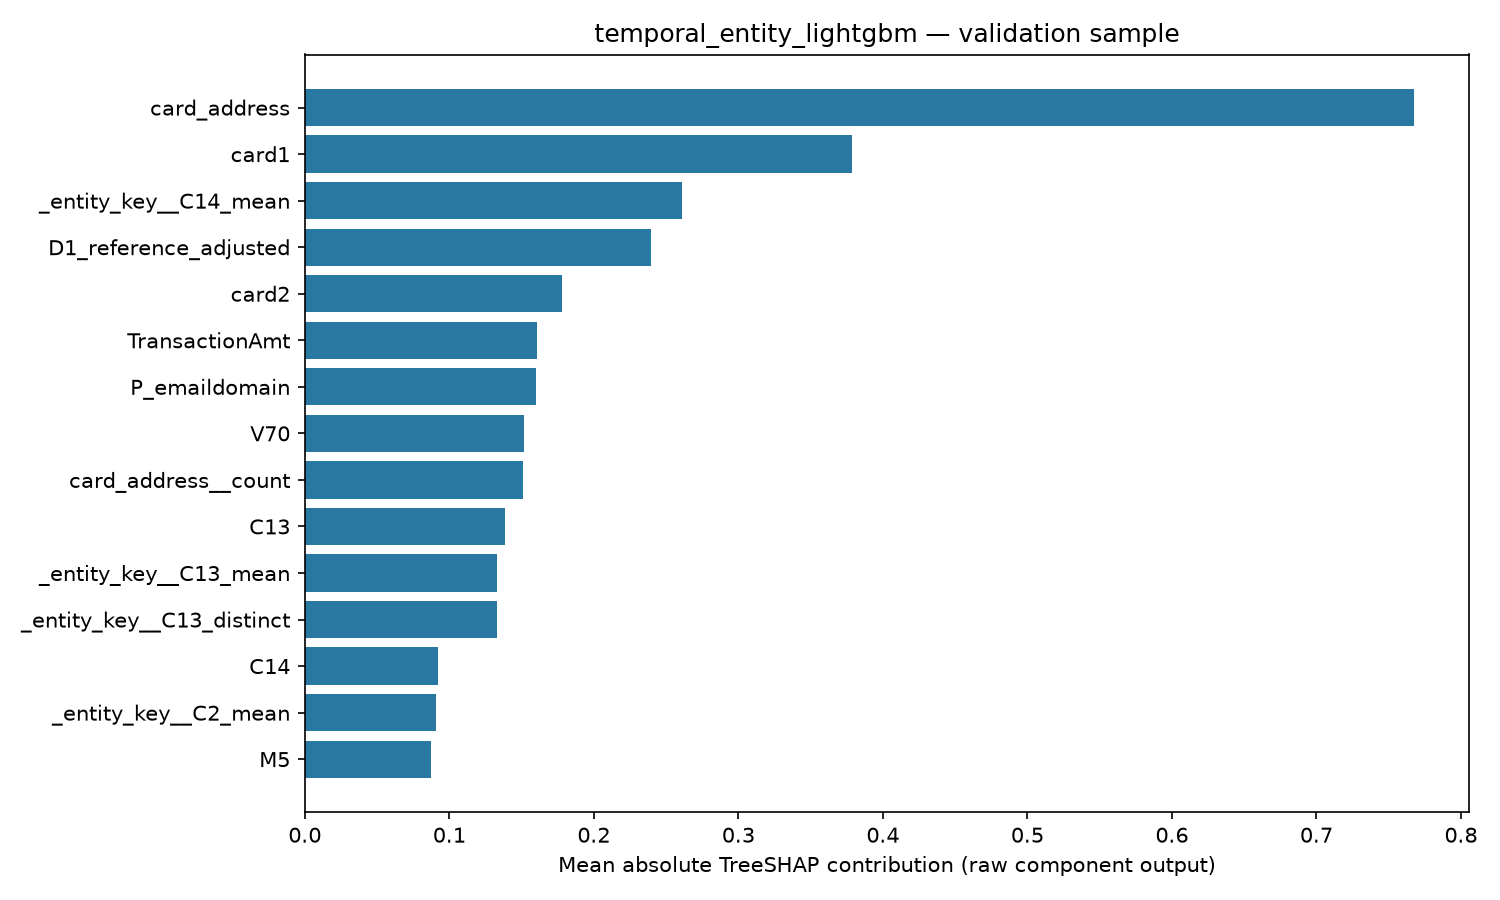

In [12]:
if RUN_TRAINING and RUN_CONTROLLED:
    frozen = json.loads((CONTROLLED_OUT / "policy.json").read_text())
    chosen = frozen["selected"]["name"]
    component = "temporal_entity_lightgbm" if chosen.startswith("blend_") else chosen
    plan = json.loads((CONTROLLED_OUT / "plan.json").read_text())
    sample = load_labeled_period(plan["split_manifest"], "validation").sample(n=800, random_state=42).head(500)
    if component.startswith("reference_"):
        state = joblib.load(CONTROLLED_OUT / "reference_state.joblib")
        matrix = transform_reference(sample.drop(columns="isFraud"), state)
        feature_names = state["preprocessor"].get_feature_names_out().tolist()
    else:
        state = joblib.load(CONTROLLED_OUT / "temporal_entity_state.joblib")
        matrix = transform_temporal_entity(sample.drop(columns="isFraud"), state)
        feature_names = state["columns"]
    if "lightgbm" in component:
        booster = lgb.Booster(model_file=str(CONTROLLED_OUT / (component + ".txt")))
        contributions = booster.predict(matrix, pred_contrib=True, num_threads=4)
        raw_scores = booster.predict(matrix, raw_score=True, num_threads=4)
    else:
        model = xgb.XGBClassifier(); model.load_model(CONTROLLED_OUT / (component + ".ubj"))
        matrix = numeric_tree_matrix(matrix) if isinstance(matrix, pd.DataFrame) else matrix
        dmatrix = xgb.DMatrix(matrix, nthread=4)
        tree_range = (0, model.best_iteration + 1)
        contributions = model.get_booster().predict(dmatrix, pred_contribs=True, iteration_range=tree_range)
        raw_scores = model.get_booster().predict(dmatrix, output_margin=True, iteration_range=tree_range)
    np.testing.assert_allclose(contributions.sum(axis=1), raw_scores, rtol=1e-4, atol=1e-4)
    importance = pd.DataFrame({"feature": feature_names,
        "mean_absolute_shap": np.abs(contributions[:, :-1]).mean(axis=0)})
    top = importance.nlargest(15, "mean_absolute_shap").iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.feature, top.mean_absolute_shap)
    ax.set(xlabel="Mean absolute TreeSHAP contribution (raw component output)", title=component)
    fig.tight_layout(); display(fig); plt.close(fig)
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["controlled_component_shap.png"])))
    print(REPORTED["controlled"]["verification"])


### Split diagnostic: why random and chronological scores differ

A separate stratified random 60/20/20 diagnostic uses the same reference XGBoost and temporal/entity LightGBM recipes, with transformations fitted on training only and early stopping/thresholds selected on validation. Neither diagnostic model changes the chronological winner. Its policy was already frozen, and the diagnostic verified that it remained unchanged.

The adapted reference XGBoost achieved **0.9444 ROC-AUC / 0.6675 average precision** on the random test split, versus **0.8793 / 0.4559** on the chronological split. This is close to the reference repository's reported random-split scores of 0.9483 / 0.6755, though its original split is 80/20 and uses test labels for early stopping and threshold selection.

The richer LightGBM achieved **0.9744 ROC-AUC / 0.8901 average precision** on the random diagnostic. These scores are not estimates of future-period detection.

About **68.6%** of proxy groups in the chronological test period were unseen in its training partition, versus **27.8%** in the random diagnostic. A proxy group is a constructed feature hypothesis, not a verified customer identity. Random splitting can make recognition of familiar groups much easier; temporal drift and the different sample composition also matter. This does not isolate every cause of the performance gap.

**Interpretation:** The primary model and metrics remain chronological. The diagnostic is a retrospective split comparison on previously used data, not an independent new evaluation or a replacement headline score.

In [ ]:
from sklearn.model_selection import train_test_split
RANDOM_OUT = ROOT / "output/notebook_run/random_diagnostic"
RUN_RANDOM_DIAGNOSTIC = False

def run_random_diagnostic():
 if (RANDOM_OUT/'plan.json').exists():raise FileExistsError('Do not overwrite a completed or running diagnostic')
 # A chronological model must already have been frozen, so this diagnostic cannot select it.
 frozen=json.loads((CONTROLLED_OUT / 'policy.json').read_text())
 RANDOM_OUT.mkdir(parents=True,exist_ok=True)
 write_result(RANDOM_OUT/'plan.json',{'created_at_utc':datetime.now(timezone.utc).isoformat(),
  'seed':42,'split':'stratified random 60/20/20','models':['reference_xgboost_500','temporal_entity_lightgbm'],
  'purpose':'Paired split diagnostic; no selection or update of chronological models',
  'chronological_policy_frozen_at':frozen['frozen_at_utc'],
  'preprocessing':'fit only on random training partition; validation early stopping and thresholds',
  'interpretation':'Random row splits can share entities across periods; this does not estimate future-period performance',
  'data_previously_used':True})
 print('Random diagnostic plan frozen; chronological policy will remain unchanged.',flush=True)
 transaction=pd.read_csv(ROOT/'data/train_transaction.csv');identity=pd.read_csv(ROOT/'data/train_identity.csv')
 frame=transaction.merge(identity,on='TransactionID',how='left',validate='one_to_one');del transaction,identity
 idx=np.arange(len(frame));target=frame.isFraud.to_numpy()
 train_idx,remaining=train_test_split(idx,test_size=.4,stratify=target,random_state=42)
 valid_idx,test_idx=train_test_split(remaining,test_size=.5,stratify=target[remaining],random_state=42)
 train=frame.iloc[train_idx].reset_index(drop=True);valid=frame.iloc[valid_idx].reset_index(drop=True)
 test=frame.iloc[test_idx].reset_index(drop=True);del frame
 y=train.isFraud.to_numpy();yv=valid.isFraud.to_numpy();ratio=float((y==0).sum()/(y==1).sum())
 results=[];validation=[];policies={};test_unseen_proxy_fraction=None
 X,state=fit_reference(train);Xv=transform_reference(valid,state)
 model=xgb.XGBClassifier(n_estimators=500,max_depth=6,learning_rate=.05,subsample=.8,colsample_bytree=.8,
  scale_pos_weight=ratio,eval_metric='aucpr',early_stopping_rounds=20,tree_method='hist',random_state=42,n_jobs=4)
 start=time.perf_counter();print('Random-split reference XGBoost...',flush=True)
 model.fit(X,y,eval_set=[(Xv,yv)],verbose=False)
 scores=model.predict_proba(Xv)[:,1];threshold=threshold_for_f1(yv,scores)
 validation.append({'name':'reference_xgboost_500',**report_metrics(yv,scores,threshold)})
 policies['reference_xgboost_500']={'threshold':threshold,'best_iteration':model.best_iteration+1}
 write_result(RANDOM_OUT/'reference_policy.json',{'frozen_at_utc':datetime.now(timezone.utc).isoformat(),**policies['reference_xgboost_500']})
 predictions=model.predict_proba(transform_reference(test.drop(columns='isFraud'),state))[:,1]
 results.append({'name':'reference_xgboost_500',**report_metrics(test.isFraud.to_numpy(),predictions,threshold)})
 print('RANDOM TEST',results[-1],flush=True)
 del X,Xv,state,model,scores,predictions
 X,state=fit_temporal_entity(train);Xv=transform_temporal_entity(valid,state)
 model=lgb.LGBMClassifier(n_estimators=1800,num_leaves=63,max_depth=-1,learning_rate=.035,
  min_child_samples=40,colsample_bytree=.75,subsample=.85,subsample_freq=1,reg_lambda=3.,
  cat_smooth=20,metric='average_precision',random_state=42,n_jobs=4,verbosity=-1)
 print('Random-split temporal/entity LightGBM...',flush=True)
 model.fit(X,y,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(100,first_metric_only=True,verbose=False)])
 scores=model.predict_proba(Xv)[:,1];threshold=threshold_for_f1(yv,scores)
 validation.append({'name':'temporal_entity_lightgbm',**report_metrics(yv,scores,threshold)})
 policies['temporal_entity_lightgbm']={'threshold':threshold,'best_iteration':model.best_iteration_}
 write_result(RANDOM_OUT/'entity_policy.json',{'frozen_at_utc':datetime.now(timezone.utc).isoformat(),**policies['temporal_entity_lightgbm']})
 predictions=model.predict_proba(transform_temporal_entity(test.drop(columns='isFraud'),state))[:,1]
 results.append({'name':'temporal_entity_lightgbm',**report_metrics(test.isFraud.to_numpy(),predictions,threshold)})
 print('RANDOM TEST',results[-1],flush=True)
 proxy=(test.card1.astype('string').fillna('__missing__')+'_'+test.addr1.astype('string').fillna('__missing__')+'_'+np.floor(test.TransactionDT/86400-test.D1).astype('string').fillna('__missing__'))
 test_unseen_proxy_fraction=float((~proxy.isin(state['aggregates']['_entity_key']['count'])).mean())
 pd.DataFrame(validation).to_csv(RANDOM_OUT/'validation_metrics.csv',index=False)
 pd.DataFrame(results).to_csv(RANDOM_OUT/'test_metrics.csv',index=False)
 write_result(RANDOM_OUT/'summary.json',{'completed_at_utc':datetime.now(timezone.utc).isoformat(),
  'train_rows':len(train),'validation_rows':len(valid),'test_rows':len(test),
  'test_fraud_prevalence':float(test.isFraud.mean()),'test_unseen_proxy_fraction':test_unseen_proxy_fraction,'diagnostic_only':True,'data_previously_used':True,
  'chronological_policy_unchanged':frozen==json.loads((CONTROLLED_OUT / 'policy.json').read_text()),
  'policies':policies,'runtime_seconds':time.perf_counter()-start})

In [11]:
if RUN_TRAINING and RUN_RANDOM_DIAGNOSTIC:
    run_random_diagnostic()
    chronological = pd.read_csv(CONTROLLED_OUT / "test_metrics.csv")
    randomized = pd.read_csv(RANDOM_OUT / "test_metrics.csv")
    paired_scores = chronological[chronological.name.isin(randomized.name)].merge(
        randomized, on="name", validate="one_to_one", suffixes=("_chronological", "_random"))
    display(paired_scores[["name", "roc_auc_chronological", "roc_auc_random",
                           "average_precision_chronological", "average_precision_random"]].round(4))
else:
    display(pd.DataFrame(REPORTED["random_diagnostic"]["paired"]).round(4))


name,roc_auc_chronological,roc_auc_random,average_precision_chronological,average_precision_random
reference_xgboost_500,0.8793,0.9444,0.4559,0.6675
temporal_entity_lightgbm,0.8771,0.9744,0.5233,0.8901


## 8. Initial-model SHAP explanations

Tree SHAP uses up to 500 uniformly selected validation rows. The beeswarm summarizes learned associations on the model's raw-output scale, not causal effects. Anonymous C/V feature names do not reveal their exact semantics.

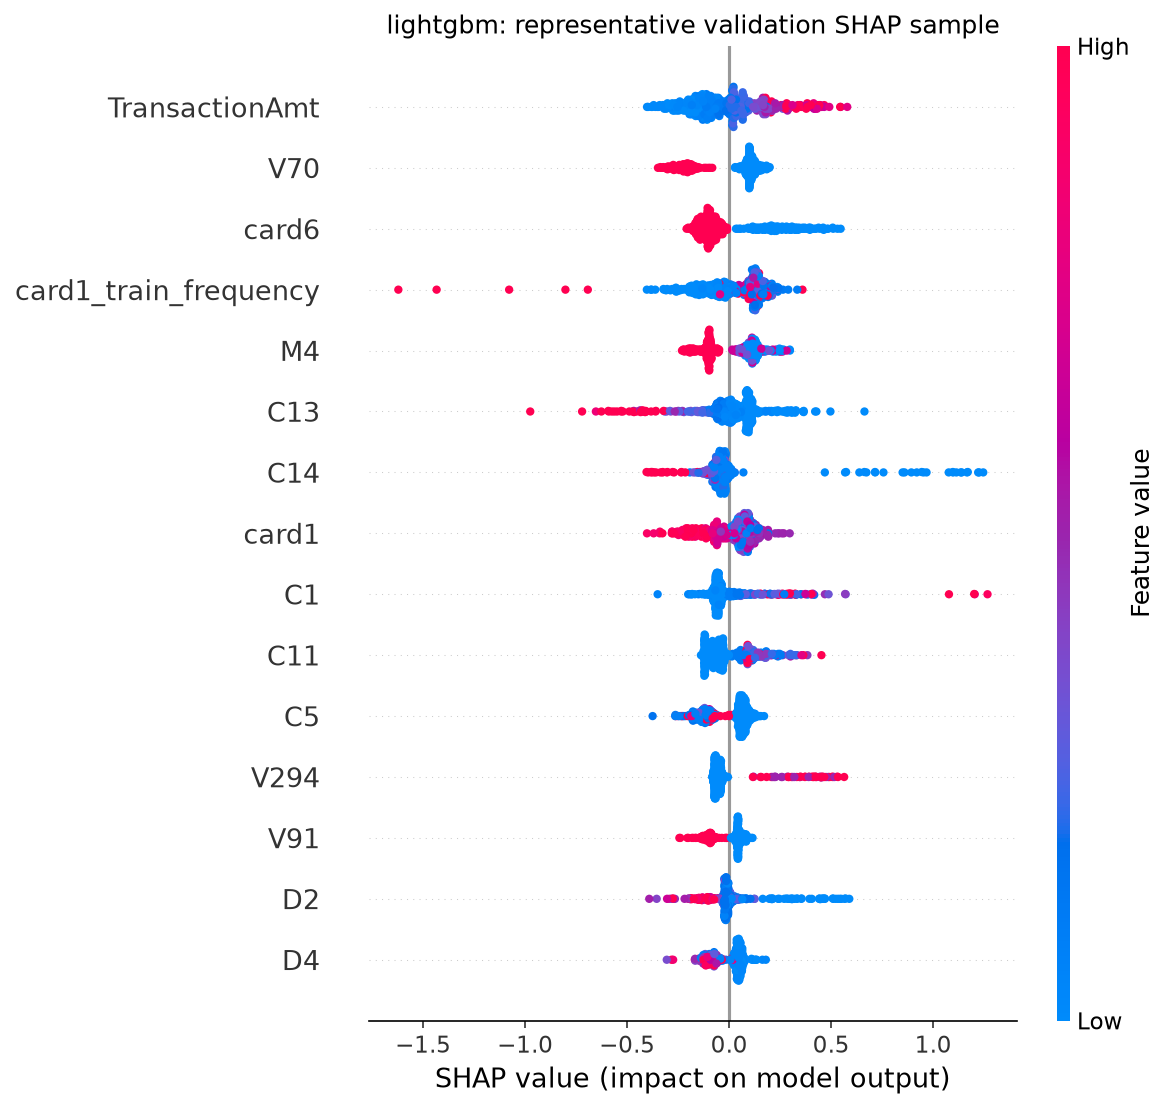

In [5]:
if RUN_TRAINING:
    display(pd.read_csv(DEFAULT_OUT / "shap_importance.csv").head(15))
    display(Image(filename=str(DEFAULT_OUT / "shap_summary.png")))
else:
    display(Image(data=base64.b64decode(REPORTED["figures"]["shap_summary.png"])))

## 9. Raw-record inference

The tree bundle includes fitted feature mappings, preprocessing, models, and the threshold policy. The autoencoder saves weights and preprocessing separately. Scoring fits nothing on incoming records. Input must be the joined raw schema, including TransactionID; labels are unnecessary.

Weighted tree scores are not calibrated probabilities. Reconstruction errors are anomaly scores rather than probabilities. Only load trusted local artifacts.

In [ ]:
if RUN_TRAINING:
    records = pd.read_csv(ROOT / "data/train_transaction.csv", nrows=8).drop(columns="isFraud")
    identity = pd.read_csv(ROOT / "data/train_identity.csv")
    records = records.merge(identity.loc[identity.TransactionID.isin(records.TransactionID)],
                            on="TransactionID", how="left", validate="one_to_one")
    del identity
    tree_bundle = joblib.load(DEFAULT_OUT / "model_bundle.joblib")
    display(score_records(tree_bundle, records))
    display(score_anomaly_records(records, AE_OUT))
else:
    print("Scoring demo requires the artifacts produced by RUN_TRAINING=True.")

## 10. Local experiment tracking

The cell below logs actual saved settings, validation metrics, and final-test metrics to local MLflow after training. Runs are tagged as post-run imports. Nothing is sent to a hosted tracking account. This is optional and does not change model selection or thresholds.

In [ ]:
import os
os.environ.setdefault("MLFLOW_ENABLE_TELEMETRY", "false")

if RUN_TRAINING:
    import mlflow
    tracking_dir = ROOT / "output/notebook_run/tracking"
    tracking_dir.mkdir(parents=True, exist_ok=True)
    mlflow.set_tracking_uri("sqlite:///" + str(tracking_dir / "mlflow.db"))
    experiment_name = "transaction-risk-scoring"
    if mlflow.get_experiment_by_name(experiment_name) is None:
        mlflow.create_experiment(experiment_name,
            artifact_location=(tracking_dir / "artifacts").as_uri())
    mlflow.set_experiment(experiment_name)
    for entry in json.loads((DEFAULT_OUT / "experiment_log.json").read_text()):
        with mlflow.start_run(run_name=entry["model"] + "-validation"):
            mlflow.set_tags({"logging_method": "post_run_import", "stage": "validation"})
            mlflow.log_params({k: str(v) for k, v in entry["params"].items()})
            mlflow.log_metrics({k: v for k, v in entry["validation"].items() if k != "model"})
            mlflow.log_metric("fit_seconds", entry["fit_seconds"])
    with mlflow.start_run(run_name="supervised-final-evaluation"):
        mlflow.set_tags({"logging_method": "post_run_import", "stage": "test"})
        final = json.loads((DEFAULT_OUT / "run_summary.json").read_text())
        mlflow.log_metrics({k: v for k, v in final["primary_test_metrics"].items() if k != "model"})
        for name in ["decision_policy.json", "environment.json", "precision_recall.png", "shap_summary.png"]:
            mlflow.log_artifact(str(DEFAULT_OUT / name))
    ae_run = json.loads((AE_OUT / "run_summary.json").read_text())
    for split in ["validation", "test"]:
        with mlflow.start_run(run_name="autoencoder-" + split):
            mlflow.set_tags({"logging_method": "post_run_import", "stage": split})
            mlflow.log_metrics(ae_run[split])
            mlflow.log_param("normal_fit_rows", ae_run["train_normal_fit_rows"])
            mlflow.log_param("numeric_features", ae_run["numeric_features"])
            mlflow.log_artifact(str(AE_OUT / "experiment_plan.json"))
    print("Local MLflow experiments recorded.")
else:
    print("Tracking runs only after reproduction training.")

if RUN_TRAINING and RUN_IMPROVEMENTS:
    followup_plan = json.loads((IMPROVEMENT_OUT / "study_plan.json").read_text())
    for row in pd.read_csv(IMPROVEMENT_OUT / "validation_candidates.csv").to_dict("records"):
        with mlflow.start_run(run_name="followup-" + row["name"]):
            mlflow.set_tags({"stage": "followup_validation", "logging_method": "post_run_import"})
            config = next(c for c in followup_plan["candidates"] if c["name"] == row["name"])
            mlflow.log_params({k: str(v) for k, v in config.items()})
            mlflow.log_metrics({k: v for k, v in row.items() if k != "name"})
    with mlflow.start_run(run_name="followup-selected-evaluation"):
        mlflow.set_tags({"stage": "followup_test", "test_period_previously_reported": "true"})
        followup_metrics = json.loads((IMPROVEMENT_OUT / "test_metrics.json").read_text())
        mlflow.log_metrics({k: v for k, v in followup_metrics.items()
                           if isinstance(v, (int, float)) and not isinstance(v, bool)})
        mlflow.log_artifact(str(IMPROVEMENT_OUT / "decision_policy.json"))
        mlflow.log_artifact(str(IMPROVEMENT_OUT / "selected_model.txt"))


if RUN_TRAINING and RUN_CONTROLLED:
    for row in pd.read_csv(CONTROLLED_OUT / "validation_metrics.csv").to_dict("records"):
        with mlflow.start_run(run_name="controlled-validation-" + row["name"]):
            mlflow.set_tags({"stage": "controlled_validation", "logging_method": "post_run_import"})
            mlflow.log_metrics({k: v for k, v in row.items() if k != "name"})
            mlflow.log_artifact(str(CONTROLLED_OUT / "plan.json"))
    frozen = json.loads((CONTROLLED_OUT / "policy.json").read_text())
    chosen = pd.read_csv(CONTROLLED_OUT / "test_metrics.csv").set_index("name").loc[frozen["selected"]["name"]]
    with mlflow.start_run(run_name="controlled-final-evaluation"):
        mlflow.set_tags({"stage": "controlled_test", "test_previously_reported": "true"})
        mlflow.log_metrics(chosen.to_dict())
        mlflow.log_artifact(str(CONTROLLED_OUT / "policy.json"))

if RUN_TRAINING and RUN_RANDOM_DIAGNOSTIC:
    for row in pd.read_csv(RANDOM_OUT / "test_metrics.csv").to_dict("records"):
        with mlflow.start_run(run_name="random-diagnostic-" + row["name"]):
            mlflow.set_tags({"stage": "random_split_diagnostic", "future_period_estimate": "false"})
            mlflow.log_metrics({k: v for k, v in row.items() if k != "name"})
            mlflow.log_artifact(str(RANDOM_OUT / "plan.json"))


## 11. Checks and limitations

Completed-run checks covered time boundaries, training-only transformations, per-record reconstruction error, native-library compatibility, and independent-process scoring. The notebook below includes lightweight assertions for the same core contracts. The consolidated notebook has not yet been executed end-to-end in a Jupyter kernel; embedded outputs come from the completed underlying runs.

- Linked transactions can remain dependent across time periods.
- Label delay and investigation bias are not modeled.
- F1-based thresholds do not model actual review capacity or verified business costs.
- Tree and autoencoder representations differ; their comparison includes that difference.
- The later autoencoder extension reuses the previously reported holdout.
- Historical velocity features, probability calibration, serving, and monitoring remain future work.

This is an offline modeling study, not a live fraud service.

In [ ]:
fixture = pd.DataFrame({"TransactionID": range(100),
    "TransactionDT": np.repeat(range(10), 10), "isFraud": [0, 1] * 50})
a, b, c = chronological_split(fixture)
assert len(a) + len(b) + len(c) == 100
assert a.TransactionDT.max() < b.TransactionDT.min()
assert b.TransactionDT.max() < c.TransactionDT.min()

normal = pd.DataFrame({"TransactionID": [1, 2, 3], "isFraud": [0, 0, 0],
    "TransactionDT": [1, 2, 3], "card1": [10, 10, 20], "TransactionAmt": [1., 2., 3.]})
builder = FraudFeatures().fit(normal)
future = normal.iloc[:2].copy(); future["card1"] = [10, 99]
assert builder.transform(future).card1_train_frequency.tolist() == [2, 0]
assert "isFraud" not in builder.transform(future)

preprocessor = NormalPreprocessor().fit(normal)
assert "card1" not in preprocessor.columns
assert np.isfinite(preprocessor.transform(future)).all()
model = AutoEncoder(4)
inputs = np.arange(28, dtype=np.float32).reshape(7, 4)
np.testing.assert_allclose(reconstruction_scores(model, inputs, 3),
                           reconstruction_scores(model, inputs, 7), rtol=1e-5)
print("Split, mapping, preprocessing, and reconstruction checks passed.")

native_fixture = pd.DataFrame({"TransactionID": [1, 2, 3], "TransactionDT": [10, 20, 30],
    "isFraud": [0, 1, 0], "TransactionAmt": [10., 20., 30.], "card1": [1, 1, 2],
    "card2": [1., np.nan, 2.], "card3": [1, 1, 1], "card5": [1, 2, 1],
    "addr1": [5., 5., np.nan], "addr2": [1, 1, 1],
    "P_emaildomain": ["a.com", None, "b.net"], "R_emaildomain": [None, "a.com", "b.net"],
    "id_01": [1., np.nan, 2.]})
_, native_state = fit_native_features(native_fixture, enriched=True)
unseen_fixture = native_fixture.iloc[:1].copy()
unseen_fixture["card1"] = 99
encoded = transform_native_features(unseen_fixture, native_state)
assert encoded.card1_train_count.iloc[0] == 0
assert pd.isna(encoded.card1.iloc[0])
assert "isFraud" not in encoded and "TransactionID" not in encoded
print("Native-category and training-only aggregate checks passed.")
